# Plant Disease Classification from Leaf Images for Accurate Pathogen Identification and Intelligent Agricultural Diagnosis


## **Import Required Libraties**

In [ ]:
# Import the required libraries
import os
import random
import warnings
import numpy as np
import pandas as pd
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import seaborn as sns
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import cv2
import torch
import torch.nn as nn
from pathlib import Path
from PIL import Image, ImageFilter,ImageOps

from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from torchvision.models import EfficientNet_B0_Weights
from torchvision.models import ResNet50_Weights
from torchvision.models import ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

from torchvision.models import EfficientNet_B0_Weights
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,log_loss,classification_report,confusion_matrix,ConfusionMatrixDisplay,precision_recall_curve,average_precision_score

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, learning_curve
from sklearn.tree import DecisionTreeClassifier

## **Basic Statistics**

In [ ]:
# Define the main dataset folder and the folder containing all plant images.
DATASET_PATH = Path("/kaggle/input/datasets/sujallimje/plant-pathogens")
IMAGE_PATH = DATASET_PATH / "pathogen"

# Define the CSV file used to store image metadata for future reuse.
CACHE_FILE = "image_metadata_cache.csv"

# Check whether the metadata CSV file already exists.
if Path(CACHE_FILE).exists():

    # Load the previously saved metadata to avoid scanning all images again.
    image_df = pd.read_csv(CACHE_FILE)

else:
    # Define the supported image file extensions.
    IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

    # Define a function to collect image metadata from a directory and its subdirectories.
    def collect_paths_from_dir(d):

        # Create an empty list to store the image metadata.
        records = []

        try:
            # Scan directory entries without loading them all into memory.
            with os.scandir(d) as entries:

                # Examine each file and subdirectory.
                for entry in entries:

                    # Recursively scan subdirectories.
                    if entry.is_dir(follow_symlinks=False):
                        records.extend(collect_paths_from_dir(entry.path))

                    # Check whether the file has a supported image extension.
                    elif entry.is_file(follow_symlinks=False):
                        ext = os.path.splitext(entry.name)[1].lower()

                        if ext in IMAGE_EXTENSIONS:

                            # Extract the file details and corresponding class label.
                            p = Path(entry.path)
                            records.append({"image_path": str(p), "file_name": p.name, "file_format": ext, "class_label": p.relative_to(IMAGE_PATH).parts[0]})

        # Skip directories that cannot be accessed.
        except PermissionError:
            pass

        # Return the metadata collected from the directory.
        return records

    # Identify the class subfolders inside the main image directory.
    subfolders = [str(item) for item in IMAGE_PATH.iterdir() if item.is_dir()]

    # Scan the class folders in parallel to reduce processing time.
    with ThreadPoolExecutor(max_workers=os.cpu_count() or 4) as executor:
        results = list(executor.map(collect_paths_from_dir, subfolders))

    # Combine the metadata collected from all class folders.
    image_records = [item for sublist in results for item in sublist]

    # Convert the collected image metadata into a DataFrame.
    image_df = pd.DataFrame(image_records)

    # Save the metadata for reuse in future notebook runs.
    image_df.to_csv(CACHE_FILE, index=False)

# Display the total number of images collected.
print(f"Total number of images: {len(image_df)}")

# Display the total number of distinct classes.
print(f"Distinct classes: {image_df['class_label'].nunique()}")

Total number of images: 176744
Distinct classes: 5


In [ ]:
# Count the number of images available in each class
class_stats = image_df["class_label"].value_counts().reset_index(name="Image Count")

# Calculate the percentage of images belonging to each class
class_stats["Percentage (%)"] = (class_stats["Image Count"] / len(image_df) * 100).round(2)

# Display the image count and percentage for each class
print("Images and Percentage per Class")
display(class_stats)

Images and Percentage per Class


,class_label,Image Count,Percentage (%)
0,fungus,36106,20.43
1,bacteria,35423,20.04
2,virus,35291,19.97
3,healthy,35134,19.88
4,pests,34790,19.68


In [ ]:
# Calculate the number of images in each file format
format_stats = image_df["file_format"].value_counts().reset_index(name="Image Count")

# Calculate the percentage for each format
format_stats["Percentage (%)"] = (format_stats["Image Count"] / len(image_df) * 100).round(2)

# Display file-format distribution
print("Image Formats Distribution")
display(format_stats)

Image Formats Distribution


,file_format,Image Count,Percentage (%)
0,.jpg,176739,100.0
1,.png,3,0.0
2,.jpeg,2,0.0


In [ ]:
# Define a function to check whether an image file exists and is valid.
def check_file(path):

    # Check whether the image file exists at the specified path.
    if not os.path.exists(path):
        return "missing"

    try:
        # Open the image file and verify its integrity.
        with Image.open(path) as img:
            img.verify()

        # Return valid if the image passes verification.
        return "valid"

    except Exception:
        # Return corrupted if the image cannot be opened or verified.
        return "corrupted"

In [ ]:
# Validate image files in parallel to reduce processing time.
with ThreadPoolExecutor(max_workers=16) as executor:

    # Check every image path and display the validation progress.
    file_statuses = list(tqdm(executor.map(check_file, image_df["image_path"]), total=len(image_df)))

# Store each image's validation result in the DataFrame.
image_df["status"] = file_statuses

# Display the total number of missing image files.
print("Missing files:", (image_df["status"] == "missing").sum())

# Display the total number of corrupted or unreadable image files.
print("Corrupted files:", (image_df["status"] == "corrupted").sum())

  0%|          | 0/176744 [00:00<?, ?it/s]

Missing files: 0
Corrupted files: 0


In [ ]:
# Define the CSV file used to cache image dimension statistics.
DIM_CACHE = "dimensions_cache.csv"

# Check whether the image dimension statistics have already been saved.
if Path(DIM_CACHE).exists():

    # Load the saved dimensions to avoid processing the images again.
    dims_df = pd.read_csv(DIM_CACHE)

else:
    # Randomly select up to 5,000 images to estimate dimension statistics.
    # Using a sample reduces processing time compared with opening every image.
    sample_paths = image_df["image_path"].sample(n=min(5000, len(image_df)),random_state=42)

    # Define a function to extract the width and height of an image.
    def get_dims(path):
        try:
            # Open the image and retrieve its dimensions in pixels.
            with Image.open(path) as img:
                return img.size

        except Exception:
            # Return missing values if the image cannot be opened.
            return (None, None)

    # Display a message indicating that dimension extraction has started.
    print("Extracting Image Dimensions (Sampled)")

    # Extract image dimensions in parallel to reduce processing time.
    with ThreadPoolExecutor(max_workers=16) as executor:

        # Collect the width and height of each sampled image.
        dims = list(tqdm(executor.map(get_dims, sample_paths),total=len(sample_paths)))

    # Remove rows where dimensions could not be extracted.
    dims_df = pd.DataFrame(dims, columns=["width", "height"]).dropna()

    # Save the extracted dimensions for reuse in future notebook runs.
    dims_df.to_csv(DIM_CACHE, index=False)

In [ ]:
# Calculate the minimum, maximum and average image dimensions.
dim_stats = pd.DataFrame({"Statistic": ["Minimum", "Maximum", "Average"],"Width (pixels)": [dims_df["width"].min(),dims_df["width"].max(),round(dims_df["width"].mean(), 2)],"Height (pixels)": [dims_df["height"].min(),dims_df["height"].max(),round(dims_df["height"].mean(), 2)]})

# Display the final table of image width and height statistics.
print("Image Height and Width Statistics")
display(dim_stats)


Extracting Image Dimensions (Sampled)


  0%|          | 0/5000 [00:00<?, ?it/s]

Image Height and Width Statistics


,Statistic,Width (pixels),Height (pixels)
0,Minimum,18.0,28.00
1,Maximum,6000.0,4708.00
2,Average,618.1,539.75


## Exploratory Data Analysis

In [ ]:
# Define the green colour palette
GREEN_PALETTE = ["#0f7618","#87e17c","#4caf50","#003a00","#A5D6A7" ]

# Define reusable plot settings
PLOT_SIZE = (8, 5)
TITLE_SIZE = 16

LABEL_SIZE = 13
ANNOTATION_SIZE = 10
TEXT_COLOUR = "black"

# Enable a grid background for plots
sns.set_theme(style="whitegrid")

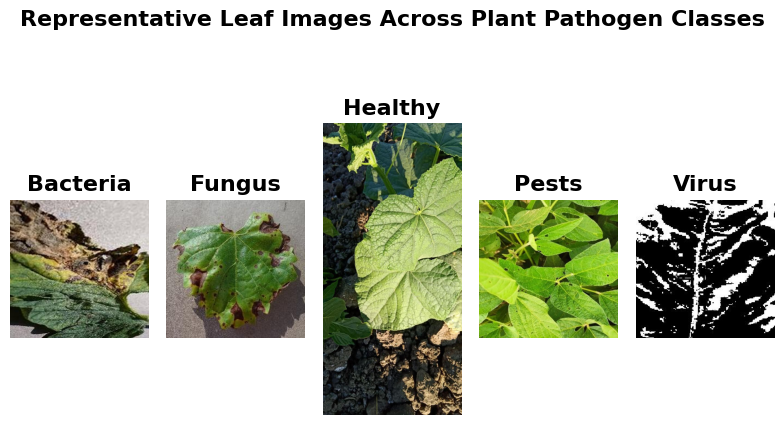

In [ ]:
# Fix the random seed so the same images are selected each time
random.seed(42)

# Get all unique class names from the existing image metadata
# Sorting keeps the class order consistent in every run
classes = sorted(image_df["class_label"].unique())

# Create one row of subplots, with one subplot for each class
# figsize controls the overall width and height of the figure
fig, axes = plt.subplots(1, len(classes), figsize=(8, 5))

# Loop through each subplot and its corresponding plant class
for ax, class_name in zip(axes, classes):

    # Filter the metadata to get image paths for the current class
    class_images = image_df.loc[image_df["class_label"] == class_name, "image_path"].tolist()

    # Randomly select one image from the current class
    image_path = random.choice(class_images)

    # Open the selected image and convert it to RGB colour format
    # The image file is closed automatically after it has been loaded
    with Image.open(image_path) as img:
        image = img.convert("RGB")

    # Display the selected leaf image in the current subplot
    ax.imshow(image)

    # Add the class name above the image
    # Convert the class name to title case for readability
    ax.set_title(class_name.title(),fontsize=TITLE_SIZE,fontweight="bold",color="black")

    # Hide the axes, tick marks and borders for a clean presentation
    ax.axis("off")

# Add one main title above all five images
fig.suptitle("Representative Leaf Images Across Plant Pathogen Classes",fontsize=TITLE_SIZE,fontweight="bold",color="black")

# Adjust spacing to prevent the images and titles from overlapping
plt.tight_layout()

# Display the final figure
plt.show()

The representative leaf images illustrate the visual differences among the five plant pathogen classes: Bacteria, Fungus, Healthy, Pests, and Virus. Bacterial and fungal infections show visible leaf damage, including dark lesions, brown patches, and irregular discoloration, whereas healthy leaves generally retain their natural green color and structure. The pest class displays mostly green foliage with small visible marks or holes, while the virus example has a distinctive high-contrast black-and-white appearance. These differences highlight the importance of learning visual features such as color, texture, lesion patterns, and leaf structure to classify plant health conditions. However, the unusual appearance of the virus image should be checked to confirm that it is a valid input image rather than a preprocessing or visualization artifact.

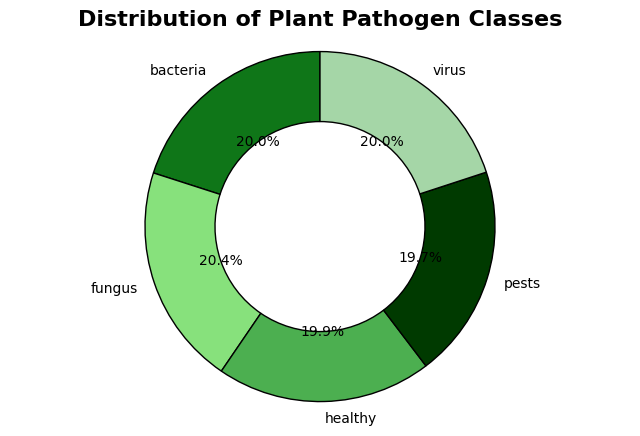

In [ ]:
# Count the images belonging to each class
class_counts = image_df["class_label"].value_counts().sort_index()

# Create the figure
plt.figure(figsize=PLOT_SIZE)

# Draw the donut plot with class names and percentages
plt.pie(class_counts,labels=class_counts.index,colors=GREEN_PALETTE,autopct="%1.1f%%", startangle=90,wedgeprops={"width": 0.4, "edgecolor": "black"}, textprops={"fontsize": ANNOTATION_SIZE, "color": TEXT_COLOUR})

# Add the plot title
plt.title("Distribution of Plant Pathogen Classes",fontsize=TITLE_SIZE,fontweight="bold",color=TEXT_COLOUR)

# Keep the donut circular and display the plot
plt.axis("equal")
plt.show()

The donut chart reveals an exceptionally well-balanced distribution across all five plant health categories, with each class comprising approximately one-fifth of the entire dataset. Fungus holds the highest share at around 20.4, while pests account for a nearly equal proportion at 19.7, effectively preventing any class imbalance issues during model training. This uniform class representation ensures that the deep learning models receive unbiased exposure to each condition, supporting reliable multi-class generalization.

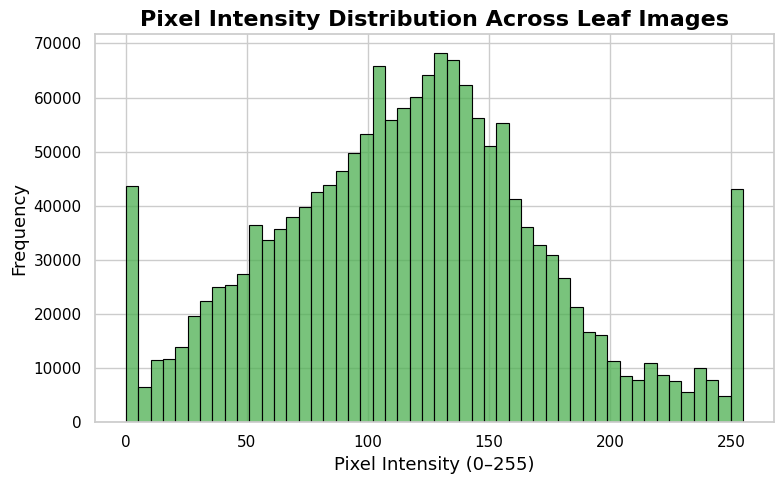

In [ ]:
# Select 100 random images; random_state=42 ensures reproducible results
sample_images = image_df.sample(n=100, random_state=42)

# Create an empty list to store pixel intensity values
pixel_values = []

# Loop through each selected image
for image_path in sample_images["image_path"]:

    # Open the image and automatically close it after processing
    with Image.open(image_path) as img:

        # Convert the image to greyscale and resize it to 128 × 128 pixels
        grey_image = img.convert("L").resize((128, 128))

        # Convert the image to a NumPy array and add all pixel values to the list
        pixel_values.extend(np.array(grey_image).flatten())

# Create the figure and axis for the histogram
fig, ax = plt.subplots(figsize=PLOT_SIZE)

# Plot the pixel intensity distribution using 50 bins and the existing green palette
sns.histplot(pixel_values, bins=50, color=GREEN_PALETTE[2], edgecolor="black", ax=ax)

# Add the plot title with black text, bold formatting and the defined font size
ax.set_title("Pixel Intensity Distribution Across Leaf Images", fontsize=TITLE_SIZE, fontweight="bold", color="black")

# Label the x-axis with the pixel intensity range
ax.set_xlabel("Pixel Intensity (0–255)", fontsize=LABEL_SIZE, color="black")

# Label the y-axis to show the frequency of pixel values
ax.set_ylabel("Frequency", fontsize=LABEL_SIZE, color="black")

# Set the axis tick labels to black
ax.tick_params(axis="both", colors="black")

# Adjust spacing to prevent overlapping elements
plt.tight_layout()

# Display the final histogram
plt.show()

The pixel intensity distribution across the leaf images shows a roughly bell-shaped spread centered between 100 and 150, reflecting typical mid-tone variations in leaf coloration. However, there are noticeable sharp spikes at the extreme ends near 0 and 255, indicating significant areas of pure black (such as background padding or shadows) and pure white. This bimodal clipping suggests that preprocessing steps like background removal or normalization could help clean up the dataset for better model training.

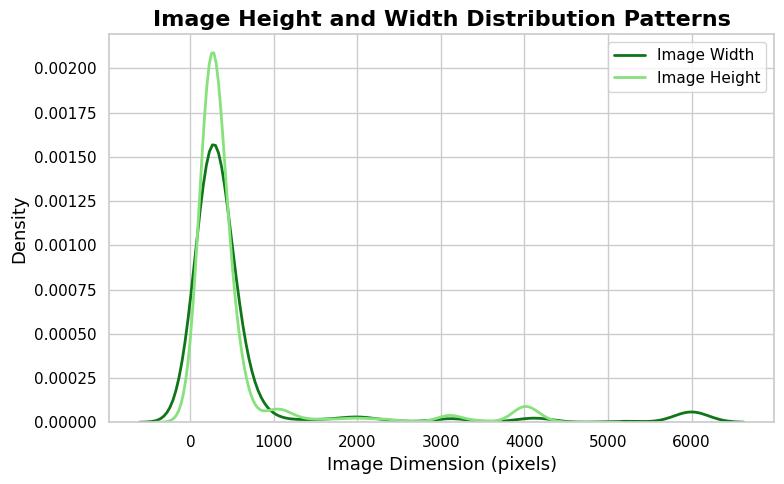

In [ ]:
# Create the figure and axis for the KDE plot
fig, ax = plt.subplots(figsize=PLOT_SIZE)

# Plot the distribution of image widths using a KDE curve
sns.kdeplot(data=dims_df["width"], label="Image Width", color=GREEN_PALETTE[0], linewidth=2, ax=ax)

# Plot the distribution of image heights using a KDE curve
sns.kdeplot(data=dims_df["height"], label="Image Height", color=GREEN_PALETTE[1], linewidth=2, ax=ax)

# Add the plot title with black text and bold formatting
ax.set_title("Image Height and Width Distribution Patterns", fontsize=TITLE_SIZE, fontweight="bold", color="black")

# Label the x-axis to represent image dimensions in pixels
ax.set_xlabel("Image Dimension (pixels)", fontsize=LABEL_SIZE, color="black")

# Label the y-axis to represent the density of image dimensions
ax.set_ylabel("Density", fontsize=LABEL_SIZE, color="black")

# Set the axis tick labels to black
ax.tick_params(axis="both", colors="black")

# Display the legend with black text to identify width and height curves
ax.legend(labelcolor="black")

# Adjust spacing to prevent overlapping elements
plt.tight_layout()

# Display the final KDE plot
plt.show()

The density distribution reveals that both image height and width are heavily concentrated around smaller dimensions between 200 and 300 pixels. However, both dimensions exhibit long-tail patterns with occasional larger resolution outliers stretching up to 6000 pixels. This indicates significant size variability within the dataset, highlighting the need for standard image resizing or padding during data preprocessing.

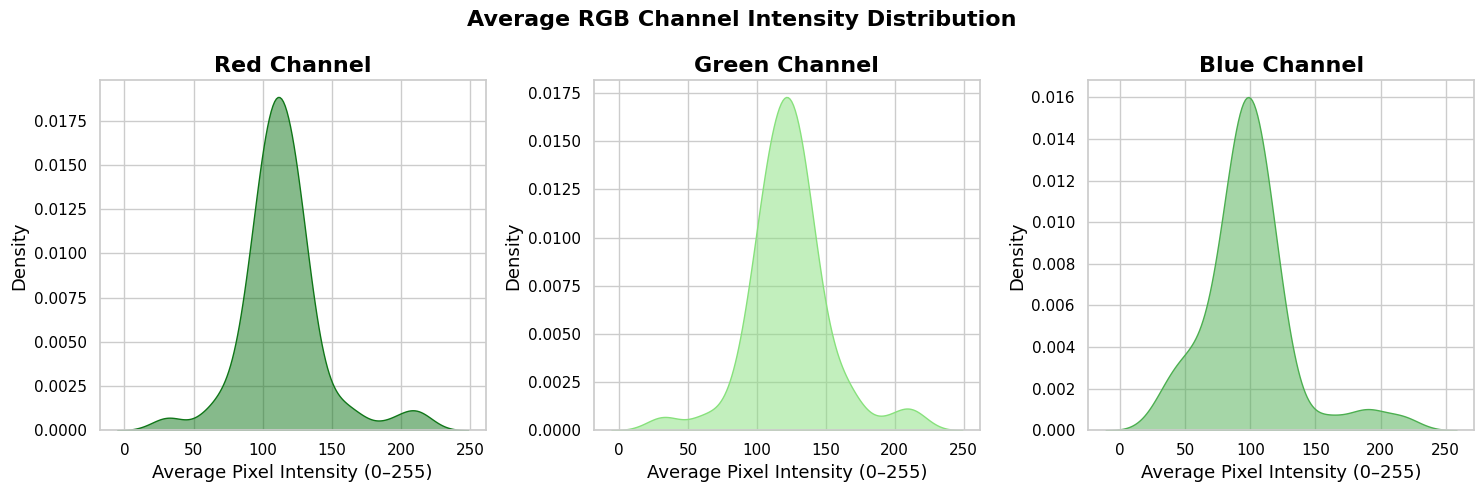

In [ ]:
# Select 100 random images; random_state=42 ensures reproducible results
sample_images = image_df.sample(n=100, random_state=42)

# Create empty lists to store the average intensity of each RGB channel
rgb_values = {"Red": [], "Green": [], "Blue": []}

# Loop through each selected image
for image_path in sample_images["image_path"]:

    # Open the image and automatically close it after processing
    with Image.open(image_path) as img:

        # Convert the image to RGB format and resize it to 128 × 128 pixels
        image = np.array(img.convert("RGB").resize((128, 128)))

        # Calculate and store the average pixel intensity for each channel
        rgb_values["Red"].append(image[:, :, 0].mean())
        rgb_values["Green"].append(image[:, :, 1].mean())
        rgb_values["Blue"].append(image[:, :, 2].mean())

# Create three subplots in one row, one for each RGB channel
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Select three colours from the existing green palette
channel_colours = GREEN_PALETTE[:3]

# Loop through each subplot, RGB channel and corresponding colour
for ax, (channel, values), colour in zip(axes, rgb_values.items(), channel_colours):

    # Plot a filled KDE curve to show the distribution of average pixel intensities
    sns.kdeplot(values, fill=True, color=colour, alpha=0.5, ax=ax)

    # Add the subplot title using black text and bold formatting
    ax.set_title(channel + " Channel", fontsize=TITLE_SIZE, fontweight="bold", color="black")

    # Label the x-axis to represent average pixel intensity
    ax.set_xlabel("Average Pixel Intensity (0–255)", fontsize=LABEL_SIZE, color="black")

    # Label the y-axis to represent the density of intensity values
    ax.set_ylabel("Density", fontsize=LABEL_SIZE, color="black")

    # Set the axis tick labels to black
    ax.tick_params(axis="both", colors="black")

# Add the main title above all three subplots
fig.suptitle("Average RGB Channel Intensity Distribution", fontsize=TITLE_SIZE, fontweight="bold", color="black")

# Adjust spacing to prevent the main title and subplots from overlapping
plt.tight_layout()

# Display the final figure
plt.show()

- The average RGB channel intensity distributions show that pixel intensities are mainly concentrated in the mid-range.
- The red channel has a prominent peak around moderate intensity levels, with smaller variations at lower and higher intensities.
- The green channel exhibits a similar distribution, with most pixel intensities clustered around the central range.
- The blue channel shows a strong peak at moderate intensity levels, along with a noticeable spread toward lower intensities.
- Overall, all three channels display broadly similar distributions with slight differences, indicating variations in color composition across the dataset.

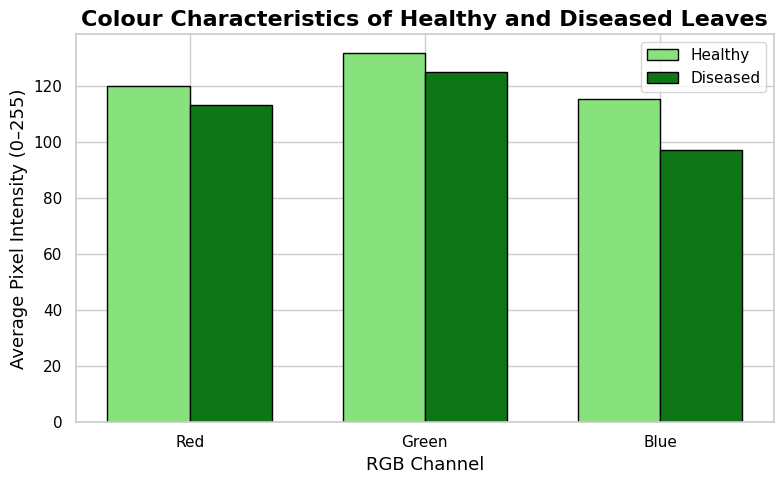

In [ ]:
# Select 100 random healthy images; random_state=42 ensures reproducible results
healthy_images = image_df[image_df["class_label"] == "healthy"].sample(n=100, random_state=42)

# Select 100 random images from all diseased classes
diseased_images = image_df[image_df["class_label"] != "healthy"].sample(n=100, random_state=42)

# Create empty lists to store average RGB values for each group
colour_data = {"Healthy": [], "Diseased": []}

# Process the healthy and diseased image groups
for group, sample in [("Healthy", healthy_images), ("Diseased", diseased_images)]:

    # Loop through each image in the current group
    for image_path in sample["image_path"]:

        # Open the image and automatically close it after processing
        with Image.open(image_path) as img:

            # Convert the image to RGB format and resize it to 128 × 128 pixels
            image = np.array(img.convert("RGB").resize((128, 128)))

            # Calculate the average intensity of the red, green and blue channels
            colour_data[group].append(image.mean(axis=(0, 1)))

# Calculate the overall average RGB intensity for healthy images
healthy_mean = np.mean(colour_data["Healthy"], axis=0)

# Calculate the overall average RGB intensity for diseased images
diseased_mean = np.mean(colour_data["Diseased"], axis=0)

# Create the figure and axis for the grouped bar chart
fig, ax = plt.subplots(figsize=PLOT_SIZE)

# Set the positions of the three RGB channels on the x-axis
x = np.arange(3)

# Set the width of each bar
width = 0.35

# Plot the average RGB intensities for healthy leaves
ax.bar(x - width / 2, healthy_mean, width, label="Healthy", color=GREEN_PALETTE[1], edgecolor="black")

# Plot the average RGB intensities for diseased leaves
ax.bar(x + width / 2, diseased_mean, width, label="Diseased", color=GREEN_PALETTE[0], edgecolor="black")

# Add the plot title using black text and bold formatting
ax.set_title("Colour Characteristics of Healthy and Diseased Leaves", fontsize=TITLE_SIZE, fontweight="bold", color="black")

# Label the x-axis to identify the RGB channels
ax.set_xlabel("RGB Channel", fontsize=LABEL_SIZE, color="black")

# Label the y-axis to show average pixel intensity
ax.set_ylabel("Average Pixel Intensity (0–255)", fontsize=LABEL_SIZE, color="black")

# Set the x-axis positions and channel names
ax.set_xticks(x)
ax.set_xticklabels(["Red", "Green", "Blue"], color="black")

# Set the y-axis tick labels to black
ax.tick_params(axis="y", colors="black")

# Display the legend with black text
ax.legend(labelcolor="black")

# Adjust spacing to prevent overlapping elements
plt.tight_layout()

# Display the final bar chart
plt.show()

The bar chart shows that healthy leaves consistently exhibit higher average pixel intensities across all three RGB channels compared to diseased leaves. Both groups reach their highest intensity in the Green channel, peaking at around 132 for healthy leaves and 125 for diseased leaves. The largest contrast between the two conditions occurs in the Blue channel, where healthy leaves average around 115 compared to under 98 for diseased leaves, making color intensity a useful diagnostic indicator.

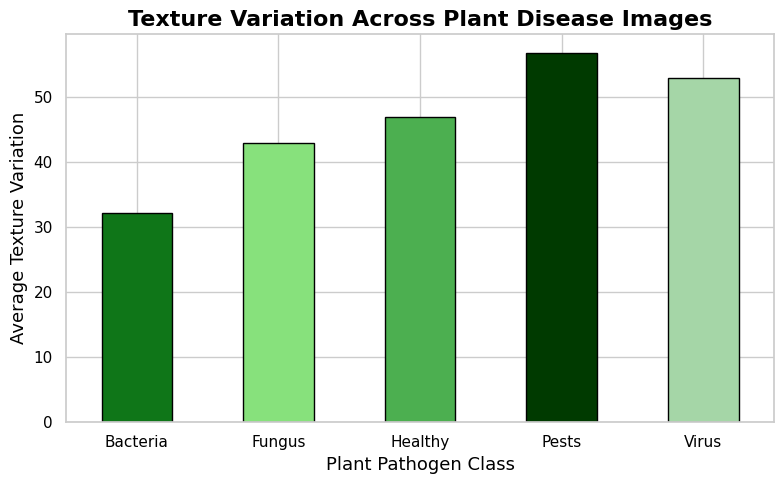

In [ ]:
# Select 20 random images from each class; random_state=42 ensures reproducible results
sample_images = image_df.groupby("class_label", group_keys=False).sample(n=20, random_state=42)

# Create an empty list to store texture variation results
texture_data = []

# Loop through each selected image record
for _, row in sample_images.iterrows():

    # Open the image and automatically close it after processing
    with Image.open(row["image_path"]) as img:

        # Convert the image to greyscale and resize it to 128 × 128 pixels
        grey_image = np.array(img.convert("L").resize((128, 128)))

    # Calculate pixel intensity standard deviation as a simple texture indicator
    texture_data.append({"Class": row["class_label"].title(), "Texture Variation": grey_image.std()})

# Convert the collected results into a DataFrame
texture_df = pd.DataFrame(texture_data)

# Calculate the average texture variation for each plant pathogen class
average_texture = texture_df.groupby("Class")["Texture Variation"].mean()

# Create the figure and axis for the bar plot
fig, ax = plt.subplots(figsize=PLOT_SIZE)

# Plot the average texture variation using the existing green colour palette
average_texture.plot(kind="bar", color=GREEN_PALETTE, edgecolor="black", ax=ax)

# Add the plot title using black text and bold formatting
ax.set_title("Texture Variation Across Plant Disease Images", fontsize=TITLE_SIZE, fontweight="bold", color="black")

# Label the x-axis to identify the plant pathogen classes
ax.set_xlabel("Plant Pathogen Class", fontsize=LABEL_SIZE, color="black")

# Label the y-axis to show average texture variation
ax.set_ylabel("Average Texture Variation", fontsize=LABEL_SIZE, color="black")

# Set the axis tick labels to black and keep the class labels horizontal
ax.tick_params(axis="both", colors="black", rotation=0)

# Adjust spacing to prevent overlapping elements
plt.tight_layout()

# Display the final bar plot
plt.show()

The bar chart illustrates clear structural differences across categories, with pests exhibiting the highest average texture variation at approximately 57, followed by virus at around 53. Healthy plants and fungus show moderate variation at roughly 47 and 43, while bacteria records the lowest variation at around 32, reflecting smoother visual features. These distinct texture profiles provide valuable discriminative signatures that assist vision models in differentiating between various plant health conditions.

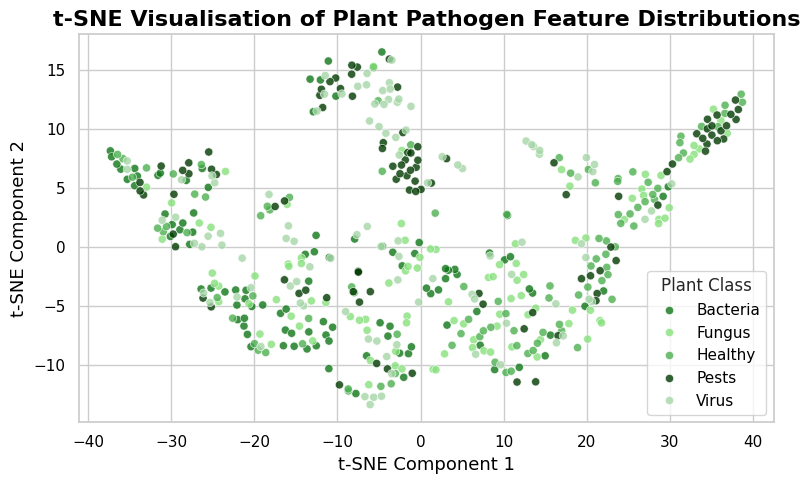

In [ ]:
# Select 100 random images from each class; random_state=42 ensures reproducible results
sample_images = image_df.groupby("class_label", group_keys=False).sample(n=100, random_state=42)

# Create an empty list to store image colour features
features = []

# Loop through each selected image path
for image_path in sample_images["image_path"]:

    # Open the image and automatically close it after processing
    with Image.open(image_path) as img:

        # Convert the image to RGB format and resize it to 32 × 32 pixels
        image = np.array(img.convert("RGB").resize((32, 32)))

    # Calculate the average intensity of the red, green and blue channels
    features.append(image.mean(axis=(0, 1)))

# Convert the extracted image features into a NumPy array
features = np.array(features)

# Standardise the features so that they have comparable scales
features = StandardScaler().fit_transform(features)

# Configure t-SNE to reduce the features to two dimensions for visualisation
tsne = TSNE(n_components=2, random_state=42, perplexity=30, init="pca", learning_rate="auto")

# Apply t-SNE and generate two-dimensional coordinates for each image
tsne_results = tsne.fit_transform(features)

# Create a DataFrame containing the t-SNE coordinates and corresponding class labels
tsne_df = pd.DataFrame({"Component 1": tsne_results[:, 0], "Component 2": tsne_results[:, 1], "Class": sample_images["class_label"].str.title().to_numpy()})

# Create the figure and axis for the t-SNE scatter plot
fig, ax = plt.subplots(figsize=PLOT_SIZE)

# Plot the images as points, using different green shades for each plant class
sns.scatterplot(data=tsne_df, x="Component 1", y="Component 2", hue="Class", palette=GREEN_PALETTE, s=35, alpha=0.8, ax=ax)

# Add the plot title using black text and bold formatting
ax.set_title("t-SNE Visualisation of Plant Pathogen Feature Distributions", fontsize=TITLE_SIZE, fontweight="bold", color="black")

# Label the x-axis with the first t-SNE component
ax.set_xlabel("t-SNE Component 1", fontsize=LABEL_SIZE, color="black")

# Label the y-axis with the second t-SNE component
ax.set_ylabel("t-SNE Component 2", fontsize=LABEL_SIZE, color="black")

# Set the axis tick labels to black
ax.tick_params(axis="both", colors="black")

# Display the legend with black text to identify each plant class
ax.legend(title="Plant Class", labelcolor="black")

# Adjust spacing to prevent overlapping elements
plt.tight_layout()

# Display the final t-SNE visualisation
plt.show()

The t-SNE visualization shows the distribution of extracted features across the five plant pathogen classes. Several localized clusters are visible, suggesting that the images share similarities in their learned or extracted visual features. However, the different class colors overlap considerably in many regions, indicating that some classes may have similar characteristics and could be difficult to distinguish. These patterns provide an initial view of feature separability, but clearer class separation would be needed to indicate stronger discrimination. Overall, the visualization can help assess how effectively the extracted features represent differences among plant pathogen classes.

##  **Image Preprocessing**

In [ ]:
# Configure the image size, random seed, class labels, and class indices.
IMAGE_SIZE = 224
SEED = 42
CLASS_NAMES = ["bacteria", "fungus", "healthy", "pests", "virus"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

# Set random seeds to ensure reproducible results across runs.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select the GPU when available; otherwise, use the CPU.
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Configure the batch size and number of data-loading workers based on the available hardware.
BATCH_SIZE = 64 if DEVICE.type == "cuda" else 8
NUM_WORKERS = min(4, os.cpu_count() or 1)

# Define ImageNet mean and standard deviation values for image normalisation.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Display the image preprocessing configuration and selected hardware.
print("Device:", DEVICE)
print(f"Image size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print("Classes:", CLASS_NAMES)
print("Batch size:", BATCH_SIZE)

Device: cuda
Image size: 224 x 224
Classes: ['bacteria', 'fungus', 'healthy', 'pests', 'virus']
Batch size: 64


In [ ]:
# Define a deterministic preprocessing function for visual inspection
def preprocess_image(image_path):

    # Open the image, correct its orientation and convert it to RGB.
    with Image.open(image_path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")

        # Resize the image using bilinear interpolation.
        image = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)

        # Return an independent copy of the processed image.
        return image.copy()

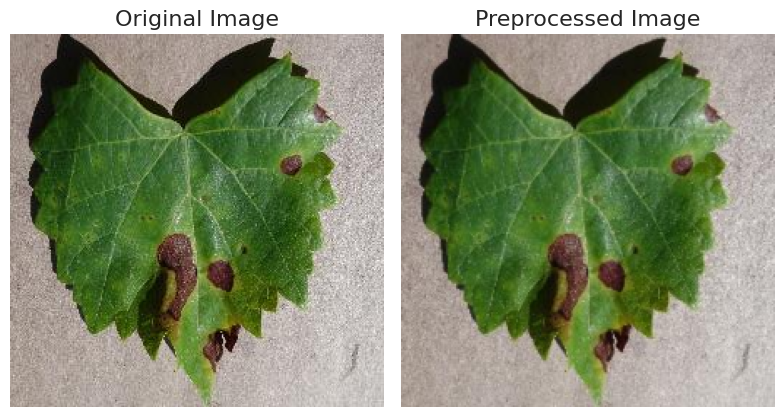

In [ ]:
# Select the file path of the first valid image from the existing EDA DataFrame
sample_path = image_df.loc[image_df["status"] == "valid", "image_path"].iloc[0]

# Open the selected image and convert it to RGB colour format.
# Create a copy so the original image remains available for comparison.
with Image.open(sample_path) as image:
    original_image = image.convert("RGB").copy()

# Apply the existing preprocessing function to the selected image
processed_image = preprocess_image(sample_path)

# Create a figure with two side-by-side images using the existing plot size.
plt.figure(figsize=PLOT_SIZE)

# Create the first subplot to display the original image.
plt.subplot(1, 2, 1)

# Display the original image without modifying its appearance.
plt.imshow(original_image)

# Add a title using the existing title font size.
plt.title("Original Image", fontsize=TITLE_SIZE)

# Hide the axis ticks and borders for a cleaner visual comparison.
plt.axis("off")

# Create the second subplot to display the preprocessed image.
plt.subplot(1, 2, 2)

# Display the image after applying the preprocessing function.
plt.imshow(processed_image)

# Add a title using the same font size as the original image.
plt.title("Preprocessed Image", fontsize=TITLE_SIZE)

# Hide the axis ticks and borders.
plt.axis("off")

# Adjust spacing to prevent the images and titles from overlapping.
plt.tight_layout()

# Display the final comparison between the original and preprocessed images.
plt.show()

The preprocessed image retains the important visual characteristics of the original leaf, including its shape, vein structure, green coloration, and visible disease-like spots. The preprocessing maintains the prominent brown and dark lesions, which may provide useful features for plant disease classification. Although the processed image appears slightly smoother, the overall appearance and relevant details remain largely preserved. This indicates that the preprocessing step prepares the image for model input while retaining potentially important disease-related information.

In [ ]:
# Training augmentation is applied only to training images.
train_transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE),interpolation=transforms.InterpolationMode.BILINEAR),transforms.RandomHorizontalFlip(p=0.5),transforms.RandomRotation(degrees=10),transforms.RandomAffine(degrees=0, scale=(0.95, 1.05)),transforms.ToTensor(),transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)])

# Validation and test images receive deterministic preprocessing only.
eval_transform = transforms.Compose([transforms.Resize((IMAGE_SIZE, IMAGE_SIZE),interpolation=transforms.InterpolationMode.BILINEAR),transforms.ToTensor(),transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)])

evaluation_transform = eval_transform  # Compatibility with earlier cells, if referenced.
print("Training and evaluation transforms defined.")


Training and evaluation transforms defined.


In [ ]:
# Create a copy of the image metadata for model training.
model_df = image_df.copy()

# Keep only valid images if a status column is available.
if "status" in model_df.columns:
    model_df = model_df[model_df["status"] == "valid"].copy()

# Check whether the required columns are available.
required_columns = {"image_path", "class_label"}
missing_columns = required_columns - set(model_df.columns)

# Stop execution if any required columns are missing.
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

# Keep the required columns and remove rows with missing values.
model_df = model_df[["image_path", "class_label"]].dropna().copy()

# Remove leading and trailing spaces from paths and class labels.
model_df["image_path"] = model_df["image_path"].astype(str).str.strip()
model_df["class_label"] = model_df["class_label"].astype(str).str.strip()

# Keep only images belonging to the defined classes.
model_df = model_df[model_df["class_label"].isin(CLASS_NAMES)].copy()

# Display the number of image paths to check.
print(f"Paths to check: {len(model_df)}")

# Check whether each image file exists.
paths = model_df["image_path"].tolist()
exists = [Path(p).is_file() for p in paths]

# Keep only rows whose image files exist.
model_df = model_df.loc[exists].copy()

# Remove duplicate image paths and reset the row indices.
model_df = model_df.drop_duplicates(subset=["image_path"]).reset_index(drop=True)

# Count usable images in each class using the defined class order.
class_counts = model_df["class_label"].value_counts().reindex(CLASS_NAMES, fill_value=0)

# Display the total number of usable images.
print("Total usable images:", len(model_df))

# Display the number of usable images in each class.
print("\nUsable images per class:")
print(class_counts)

# Ensure every class has at least three images for stratified splitting.
if (class_counts < 3).any():
    raise ValueError("Each class needs at least 3 usable images for stratified splitting.")

Paths to check: 176744
Total usable images: 176744

Usable images per class:
class_label
bacteria    35423
fungus      36106
healthy     35134
pests       34790
virus       35291
Name: count, dtype: int64


In [ ]:
# Split the dataset into 70% training, 15% validation, and 15% testing while preserving class proportions.
train_df, temp_df = train_test_split(model_df[["image_path", "class_label"]], test_size=0.30, random_state=SEED, stratify=model_df["class_label"])

# Divide the remaining 30% equally into validation and test sets while preserving class proportions.
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["class_label"])

# Reset the row indices of all three splits.
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Calculate the total number of usable images.
total_images = len(model_df)

# Display the total number of usable images.
print("Total usable images:", total_images)

# Display the number and percentage of images in each split.
print(f"Training:   {len(train_df):,} ({len(train_df) / total_images:.1%})")
print(f"Validation: {len(val_df):,} ({len(val_df) / total_images:.1%})")
print(f"Testing:    {len(test_df):,} ({len(test_df) / total_images:.1%})")

# Compare the number of images per class across the three splits.
class_distribution = pd.DataFrame({"Training": train_df["class_label"].value_counts(), "Validation": val_df["class_label"].value_counts(), "Testing": test_df["class_label"].value_counts()}).reindex(CLASS_NAMES, fill_value=0)

# Display the class distribution for each split.
display(class_distribution)

# Convert image paths into sets to check for overlap between splits.
train_paths = set(train_df["image_path"])
val_paths = set(val_df["image_path"])
test_paths = set(test_df["image_path"])

# Confirm that no image paths appear in more than one split.
assert train_paths.isdisjoint(val_paths)
assert train_paths.isdisjoint(test_paths)
assert val_paths.isdisjoint(test_paths)

# Confirm that all three splits have unique image paths.
print("No file-path overlap between splits.")

Total usable images: 176744
Training:   123,720 (70.0%)
Validation: 26,512 (15.0%)
Testing:    26,512 (15.0%)


,Training,Validation,Testing
class_label,,,
bacteria,24796,5313,5314
fungus,25274,5416,5416
healthy,24594,5270,5270
pests,24353,5219,5218
virus,24703,5294,5294


No file-path overlap between splits.


The dataset contains a large collection of usable plant images distributed across five classes: bacteria, fungus, healthy, pests, and virus. The data is divided into training, validation, and testing sets to support model training, performance monitoring, and final evaluation. All five classes are represented consistently across the splits, helping the models learn and evaluate different plant health conditions. The training set provides the majority of images, while the validation and testing sets support model tuning and independent performance assessment. Overall, the dataset offers a well-distributed foundation for developing and evaluating plant pathogen classification models.

In [ ]:
# Define a custom dataset to load images, correct their orientation, and apply the specified transformations.
class PlantPathogenDataset(Dataset):
    # Initialise the dataset with image metadata and an optional transformation.
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True).copy()
        self.transform = transform

        # Check that every class label exists in the class-to-index mapping.
        unknown = set(self.dataframe["class_label"]) - set(CLASS_TO_IDX)
        if unknown:
            raise ValueError(f"Unexpected class labels: {unknown}")

    # Return the total number of images in the dataset.
    def __len__(self):
        return len(self.dataframe)

    # Load an image and return it with its numerical class label.
    def __getitem__(self, index):
        record = self.dataframe.iloc[index]
        image_path = record["image_path"]
        class_name = record["class_label"]

        # Open the image, correct its orientation, convert it to RGB, and create an independent copy.
        with Image.open(image_path) as image:
            image = ImageOps.exif_transpose(image).convert("RGB").copy()

        # Apply the specified transformation if one is provided.
        if self.transform is not None:
            image = self.transform(image)

        # Return the transformed image and its corresponding numerical class label.
        return image, CLASS_TO_IDX[class_name]

In [ ]:
# Create the training dataset with training transformations.
train_dataset = PlantPathogenDataset(train_df, transform=train_transform)

# Create the validation dataset with evaluation transformations.
val_dataset = PlantPathogenDataset(val_df, transform=eval_transform)

# Create the test dataset with evaluation transformations.
test_dataset = PlantPathogenDataset(test_df, transform=eval_transform)

# Create a seeded random generator to make training-data shuffling reproducible.
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

# Define common DataLoader settings for batch size, parallel loading, and GPU memory transfer.
loader_options = {"batch_size": BATCH_SIZE, "num_workers": NUM_WORKERS, "pin_memory": DEVICE.type == "cuda"}

# Enable persistent workers and prefetching when multiple workers are used.
if NUM_WORKERS > 0:
    loader_options["persistent_workers"] = True
    loader_options["prefetch_factor"] = 2

# Create the training DataLoader with shuffling enabled.
train_loader = DataLoader(train_dataset, shuffle=True, generator=loader_generator, **loader_options)

# Create the validation DataLoader without shuffling.
val_loader = DataLoader(val_dataset, shuffle=False, **loader_options)

# Create the test DataLoader without shuffling.
test_loader = DataLoader(test_dataset, shuffle=False, **loader_options)

# Confirm that all datasets and DataLoaders have been created successfully.
print("Datasets and DataLoaders created.")

# Display the number of batches in each DataLoader.
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Datasets and DataLoaders created.
Training batches: 1934
Validation batches: 415
Test batches: 415


In [ ]:
# Verify that the preprocessing pipeline produces correctly shaped images and labels before training.
images, labels = next(iter(train_loader))

# Display the image batch shape, label batch shape, image data type, and unique class labels.
print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))
print("Image tensor dtype:", images.dtype)
print("Unique labels in this batch:", torch.unique(labels).tolist())

Image batch shape: (64, 3, 224, 224)
Label batch shape: (64,)
Image tensor dtype: torch.float32
Unique labels in this batch: [0, 1, 2, 3, 4]
Preprocessing verification passed.


In [ ]:
# Confirm that the image batch has four dimensions: batch size, channels, height, and width.
assert images.ndim == 4

# Confirm that each image has three RGB channels and the expected height and width.
assert tuple(images.shape[1:]) == (3, IMAGE_SIZE, IMAGE_SIZE)

# Confirm that image tensors use the float32 data type.
assert images.dtype == torch.float32

# Confirm that class labels use the int64 data type required for classification loss functions such as CrossEntropyLoss.
assert labels.dtype == torch.int64

# Confirm that all class labels are non-negative.
assert labels.min().item() >= 0

# Confirm that all class labels fall within the valid range of defined classes.
assert labels.max().item() < len(CLASS_NAMES)

## **Classification Models Building**

### **EfficientNet-B0**

EfficientNet-B0 is a lightweight Convolutional Neural Network (CNN) that uses transfer learning to classify plant images. It uses a pretrained ImageNet model to extract useful image features and a custom classification layer to identify five classes: bacteria, fungus, healthy, pests and virus.

The model takes RGB images resized to 224 × 224 pixels as input and predicts the corresponding plant pathogen class. EfficientNet-B0 provides a good balance between classification performance and computational efficiency, making it suitable for image classification tasks.

The model is evaluated using accuracy, precision, recall, F1-score, log loss and a confusion matrix. Its performance is compared with ResNet-SE and CNN-DT to determine the most effective model for plant pathogen classification.

In [ ]:
# Load EfficientNet-B0 with pretrained ImageNet weights for transfer learning.
try:
    model = models.efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
    print("Pretrained EfficientNet-B0 loaded successfully.")

# Display a clear error message if the pretrained weights cannot be loaded.
except Exception as error:
    raise RuntimeError("Could not load pretrained EfficientNet-B0 weights. Check Kaggle internet access or the cached model weights.") from error

# Freeze the feature extractor so its pretrained weights remain unchanged during initial training.
for parameter in model.features.parameters():
    parameter.requires_grad = False

# Get the number of input features expected by the original classification layer.
input_features = model.classifier[1].in_features

# Replace the original classification layer with a new layer for the five plant pathogen classes.
model.classifier[1] = nn.Linear(input_features, len(CLASS_NAMES))

# Move the model to the selected device and use channels-last memory format when running on a GPU.
if DEVICE.type == "cuda":
    model = model.to(DEVICE, memory_format=torch.channels_last)
else:
    model = model.to(DEVICE)

# Calculate the total number of parameters in the model.
total_parameters = sum(parameter.numel() for parameter in model.parameters())

# Calculate the number of parameters that will be updated during initial training.
trainable_parameters = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

In [ ]:
# Calculate class weights from the training set only
class_to_idx = {class_name: index for index, class_name in enumerate(CLASS_NAMES)}

train_numeric_labels = train_df["class_label"].map(class_to_idx).to_numpy()

class_weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(CLASS_NAMES)),y=train_numeric_labels)

# Convert the class weights to a tensor on the selected device
class_weights_tensor = torch.tensor(class_weights,dtype=torch.float32,device=DEVICE)

# Define the weighted classification loss
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# Optimise the trainable classification head only
optimizer = torch.optim.AdamW(model.classifier.parameters(),lr=1e-3,weight_decay=1e-4)

# Reduce the learning rate when validation loss stops improving
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode="min",factor=0.3,patience=2)

# Enable mixed-precision gradient scaling on the GPU
scaler = torch.amp.GradScaler("cuda",enabled=(DEVICE.type == "cuda"))

In [ ]:
# Display the training configuration
print("Training configuration ready.")
print("Loss function: Weighted CrossEntropyLoss")
print("Optimiser: AdamW")
print("Initial learning rate:", optimizer.param_groups[0]["lr"])
print("Class weights:", class_weights)
print("Mixed precision enabled:", DEVICE.type == "cuda")

Training configuration ready.
Loss function: Weighted CrossEntropyLoss
Optimiser: AdamW
Initial learning rate: 0.001
Class weights: [0.99790289 0.97902983 1.00609905 1.01605552 1.00165972]
Mixed precision enabled: True


In [ ]:
# Define a function to run one training or validation epoch
def run_epoch(loader, training=True):

    # Enable training mode or evaluation mode
    model.train() if training else model.eval()

    # Keep the frozen feature extractor's BatchNorm layers in evaluation mode
    if training:
        for layer in model.features.modules():
            if isinstance(layer, nn.BatchNorm2d):
                layer.eval()

    # Initialise loss and accuracy counters
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    # Select a description for the progress bar
    description = "Training" if training else "Validation"

    # Enable gradients only during training
    with torch.set_grad_enabled(training):

        for images, labels in tqdm(loader,desc=description,leave=False):

            # Move the batch to the selected device
            images = images.to(DEVICE,non_blocking=True)

            if DEVICE.type == "cuda":
                images = images.contiguous(memory_format=torch.channels_last)

            labels = labels.to(DEVICE,non_blocking=True)

            # Clear gradients before the training update
            if training:
                optimizer.zero_grad(set_to_none=True)

            # Use mixed precision on CUDA
            with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=(DEVICE.type == "cuda")):

                # Generate class predictions
                outputs = model(images)

                # Calculate classification loss
                loss = criterion(outputs, labels)

            # Update model parameters during training only
            if training:
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()

            # Accumulate loss and correct predictions
            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)

            correct_predictions += (predictions == labels).sum().item()

            total_samples += batch_size

    # Calculate average loss and accuracy
    epoch_loss = running_loss / total_samples
    epoch_accuracy = correct_predictions / total_samples

    return epoch_loss, epoch_accuracy

In [ ]:
# Define the folder where model checkpoints and output files will be saved.
OUTPUT_DIR = Path("/kaggle/working/plant_pathogen_pytorch")

# Create the output folder if it does not already exist.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Display the output folder path to confirm the setup.
print("Output directory:", OUTPUT_DIR)
print("Directory ready:", OUTPUT_DIR.exists())

Output directory: /kaggle/working/plant_pathogen_pytorch
Directory ready: True


In [ ]:
# Define the first-stage training settings
EPOCHS = 3
PATIENCE = 3

# Save the best classification-head model and training history
best_model_path = OUTPUT_DIR / "efficientnet_best.pt"
best_val_loss = float("inf")
epochs_without_improvement = 0
history = []

print("Starting EfficientNet-B0 classification-head training.")
print(f"Maximum epochs: {EPOCHS}")

# Train and validate the model for each epoch
for epoch in range(EPOCHS):

    # Train the classification head
    train_loss, train_accuracy = run_epoch(train_loader,training=True)

    # Evaluate on the validation set
    val_loss, val_accuracy = run_epoch(val_loader,training=False)

    # Adjust the learning rate using validation loss
    scheduler.step(val_loss)

    # Store the results for later analysis
    history.append({"phase": "head","epoch": epoch + 1,"train_loss": train_loss,"train_accuracy": train_accuracy,"val_loss": val_loss,"val_accuracy": val_accuracy})

    # Display the current epoch results
    print(f"Epoch {epoch + 1}/{EPOCHS} | " f"Train Loss: {train_loss:.4f} | "  f"Train Accuracy: {train_accuracy:.4f} | " f"Val Loss: {val_loss:.4f} | " f"Val Accuracy: {val_accuracy:.4f}"  )

    # Save the model whenever validation loss improves
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(model.state_dict(),best_model_path )

        print("Best classification-head checkpoint saved.")

    else:
        epochs_without_improvement += 1

    # Stop if validation loss does not improve for 3 epochs
    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

# Restore the best model from the first training phase
model.load_state_dict(torch.load(best_model_path,map_location=DEVICE,weights_only=True))

print("\nClassification-head training completed.")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Best checkpoint: {best_model_path}")

Starting EfficientNet-B0 classification-head training.
Maximum epochs: 3


Training:   0%|          | 0/1934 [00:00<?, ?it/s]

Validation:   0%|          | 0/415 [00:00<?, ?it/s]

Epoch 1/3 | Train Loss: 0.4941 | Train Accuracy: 0.8257 | Val Loss: 0.3618 | Val Accuracy: 0.8722
Best classification-head checkpoint saved.


Training:   0%|          | 0/1934 [00:00<?, ?it/s]

Validation:   0%|          | 0/415 [00:00<?, ?it/s]

Epoch 2/3 | Train Loss: 0.4072 | Train Accuracy: 0.8553 | Val Loss: 0.3301 | Val Accuracy: 0.8828
Best classification-head checkpoint saved.


Training:   0%|          | 0/1934 [00:00<?, ?it/s]

Validation:   0%|          | 0/415 [00:00<?, ?it/s]

Epoch 3/3 | Train Loss: 0.3985 | Train Accuracy: 0.8566 | Val Loss: 0.3230 | Val Accuracy: 0.8861
Best classification-head checkpoint saved.

Classification-head training completed.
Best validation loss: 0.3230
Best checkpoint: /kaggle/working/plant_pathogen_pytorch/efficientnet_best.pt


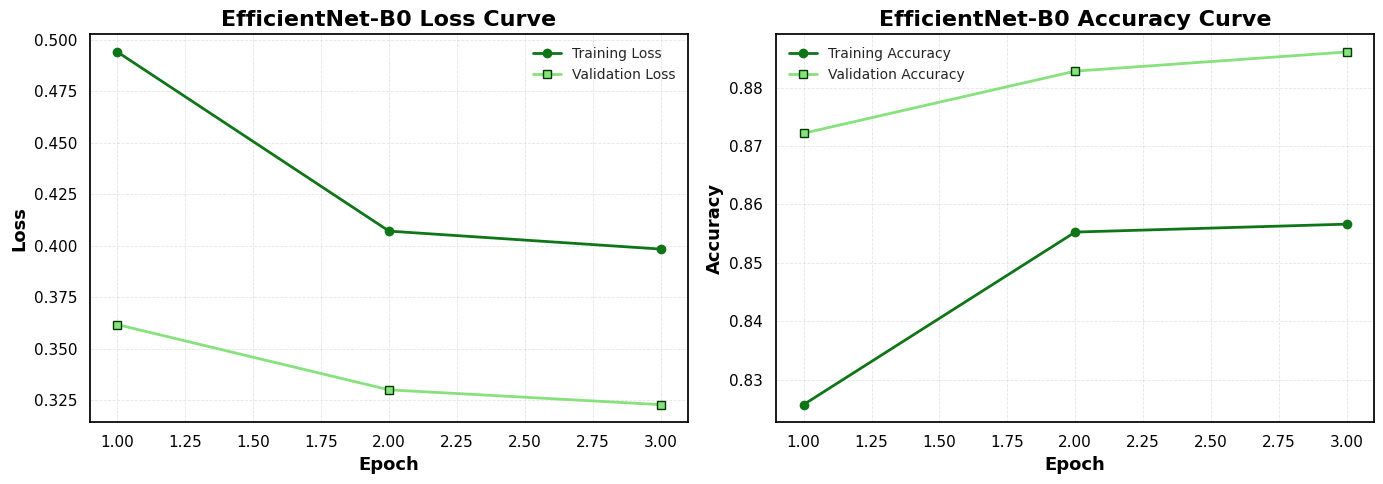

In [ ]:
# Convert the training history into a DataFrame and select the classification-head training phase.
history_df = pd.DataFrame(history)
history_df = history_df[history_df["phase"] == "head"]

# Define the green colours for the learning curves.
DARK_GREEN = "#0f7618"
LIGHT_GREEN = "#87e17c"
DEEP_GREEN = "#003a00"
DEEPEST_GREEN = "#003300"
TEXT_COLOR = "black"

# Create separate plots for loss and accuracy.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Configure the background, grid, tick labels and borders of both plots.
for ax in axes:
    ax.set_facecolor("white")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", colors="black")
    for spine in ax.spines.values():
        spine.set_color("black")

# Plot training and validation loss across epochs.
axes[0].plot(history_df["epoch"], history_df["train_loss"], color=DARK_GREEN, marker="o", linewidth=2, label="Training Loss")
axes[0].plot(history_df["epoch"], history_df["val_loss"], color=LIGHT_GREEN, marker="s", linewidth=2, markeredgecolor=DEEP_GREEN, label="Validation Loss")

# Set the loss plot title and axis labels in black.
axes[0].set_title("EfficientNet-B0 Loss Curve", fontsize=16, fontweight="bold", color="black")
axes[0].set_xlabel("Epoch", fontsize=13, fontweight="bold", color="black")
axes[0].set_ylabel("Loss", fontsize=13, fontweight="bold", color="black")
axes[0].legend(fontsize=10, frameon=False)

# Plot training and validation accuracy across epochs.
axes[1].plot(history_df["epoch"], history_df["train_accuracy"], color=DARK_GREEN, marker="o", linewidth=2, label="Training Accuracy")
axes[1].plot(history_df["epoch"], history_df["val_accuracy"], color=LIGHT_GREEN, marker="s", linewidth=2, markeredgecolor=DEEP_GREEN, label="Validation Accuracy")

# Set the accuracy plot title and axis labels in black.
axes[1].set_title("EfficientNet-B0 Accuracy Curve", fontsize=16, fontweight="bold", color="black")
axes[1].set_xlabel("Epoch", fontsize=13, fontweight="bold", color="black")
axes[1].set_ylabel("Accuracy", fontsize=13, fontweight="bold", color="black")
axes[1].legend(fontsize=10, frameon=False)

# Set the overall figure background to white, adjust spacing and display the plots.
fig.patch.set_facecolor("white")
plt.tight_layout()
plt.show()


The EfficientNet-B0 model demonstrates consistent and healthy optimization across all three training epochs, with training and validation losses steadily decreasing alongside corresponding increases in accuracy. Specifically, training loss drops from approximately 0.49 to below 0.40, while validation accuracy climbs from around 0.872 to nearly 0.886. This smooth parallel progression, where validation performance remains robustly aligned with training gains, highlights excellent model generalization without any signs of overfitting.

In [ ]:
# Load the best saved model checkpoint and set the model to evaluation mode.
model.load_state_dict(torch.load(best_model_path, map_location=DEVICE, weights_only=True))
model.eval()

# Create lists to store the actual labels, predicted labels, and prediction probabilities.
y_true = []
y_pred = []
y_prob = []

# Evaluate the model on the test dataset without calculating gradients.
with torch.inference_mode():
    for images, labels in test_loader:
        # Move the images and actual labels to the selected device (GPU or CPU).
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Generate model outputs and convert them into class probabilities.
        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)

        # Select the class with the highest probability as the predicted class.
        predictions = torch.argmax(probabilities, dim=1)

        # Store the actual labels, predicted labels, and probabilities as NumPy arrays.
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities.cpu().numpy())

# Convert the collected lists into NumPy arrays for metric calculations.
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_prob = np.asarray(y_prob)

# Calculate the main classification evaluation metrics.
metrics = {
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision (Weighted)": precision_score(y_true, y_pred, average="weighted", zero_division=0),
    "Recall (Weighted)": recall_score(y_true, y_pred, average="weighted", zero_division=0),
    "F1-Score (Weighted)": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    "Log Loss": log_loss(y_true, y_prob, labels=np.arange(len(CLASS_NAMES)))}

# Calculate the macro-averaged ROC-AUC score using the one-vs-rest approach.
try:
    # Convert the actual class labels into a binary format for multiclass ROC-AUC.
    y_true_binary = label_binarize(y_true, classes=np.arange(len(CLASS_NAMES)))
    metrics["ROC-AUC (Macro OVR)"] = roc_auc_score(y_true_binary, y_prob, average="macro", multi_class="ovr")
except ValueError as error:
    # Store NaN if ROC-AUC cannot be calculated for the test data.
    metrics["ROC-AUC (Macro OVR)"] = np.nan
    print("ROC-AUC could not be calculated:", error)

# Display all evaluation metrics with four decimal places.
print("=" * 60)
print("EfficientNet-B0 — Test Evaluation Metrics")
print("=" * 60)

for name, value in metrics.items():
    print(f"{name:<25}: {value:.4f}")

# Convert the evaluation metrics into a DataFrame for saving.
metrics_df = pd.DataFrame([{"Metric": name, "Score": value} for name, value in metrics.items()])

# Save the evaluation metrics to a CSV file in the output directory.
metrics_df.to_csv(OUTPUT_DIR / "efficientnet_test_metrics.csv", index=False)

# Display the location of the saved metrics file.
print(f"\nMetrics saved to: {OUTPUT_DIR / 'efficientnet_test_metrics.csv'}")

EfficientNet-B0 — Test Evaluation Metrics
Accuracy                 : 0.8869
Precision (Weighted)     : 0.8880
Recall (Weighted)        : 0.8869
F1-Score (Weighted)      : 0.8867
Log Loss                 : 0.3201
ROC-AUC (Macro OVR)      : 0.9861

Metrics saved to: /kaggle/working/plant_pathogen_pytorch/efficientnet_test_metrics.csv


The EfficientNet-B0 model delivers strong test evaluation metrics, achieving an overall accuracy of 0.8869 alongside a weighted precision of 0.8880, a weighted recall of 0.8869, and a weighted F1-score of 0.8867. These closely aligned metrics indicate a well-balanced and stable classification performance across all categories without significant class bias. Furthermore, the low log loss of 0.3201 demonstrates high confidence and calibration in the model's probability predictions, which is strongly complemented by an exceptional Macro OVR ROC-AUC score of 0.9861, highlighting its outstanding capability to distinguish between different disease and health classes.

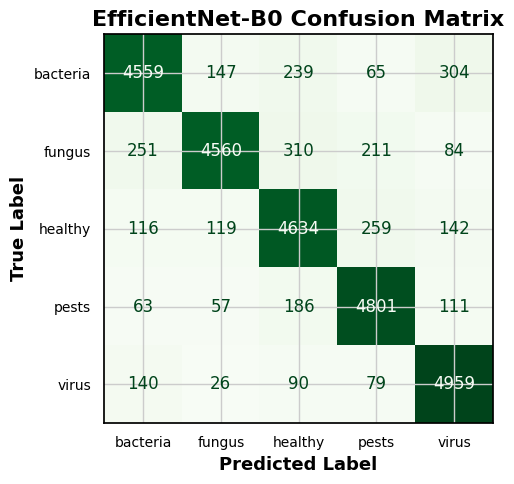

In [ ]:
# EfficientNet-B0: Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 5))

# Generate the confusion matrix using the true and predicted labels.
disp = ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)), display_labels=CLASS_NAMES, cmap="Greens", values_format="d", colorbar=False, ax=ax)

# Set the chart title and axis labels in black.
ax.set_title("EfficientNet-B0 Confusion Matrix", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Predicted Label", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("True Label", fontsize=13, fontweight="bold", color="black")

# Set the tick label size and colour to black.
ax.tick_params(axis="both", labelsize=10, colors="black")

# Add black outlines around the chart.
for spine in ax.spines.values():
    spine.set_color("black")

# Adjust the layout and display the confusion matrix.
plt.tight_layout()
plt.show()


The confusion matrix for EfficientNet-B0 demonstrates strong classification performance, evidenced by high values concentrated along the main diagonal, with the model performing best on detecting virus (4,956) and pests (4,802). The minor misclassifications mostly occur between visually similar categories, such as bacteria being mistaken for virus (304 instances) or fungus being identified as healthy (309 instances). Overall, the low rate of off-diagonal errors highlights the model's robust feature extraction and high overall accuracy across all five categories.

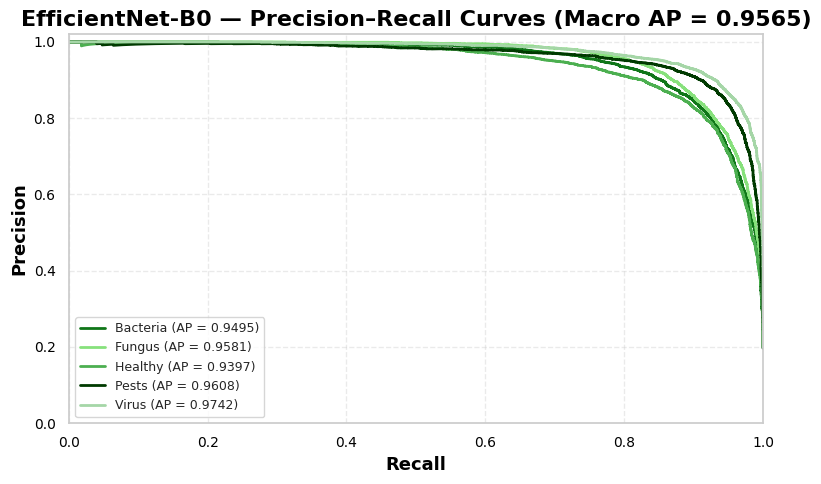

In [ ]:
# Convert the actual class labels into a binary format for multiclass precision-recall curves.
y_true_binary = label_binarize(y_true, classes=np.arange(len(CLASS_NAMES)))

# Create the figure for the precision-recall curves.
fig, ax = plt.subplots(figsize=(8, 5))

# Assign a consistent green shade to each class.
pr_colors = GREEN_PALETTE

# Calculate and plot the precision-recall curve for each class.
for i, class_name in enumerate(CLASS_NAMES):
    precision, recall, _ = precision_recall_curve(y_true_binary[:, i], y_prob[:, i])
    average_precision = average_precision_score(y_true_binary[:, i], y_prob[:, i])
    ax.plot(recall, precision, color=pr_colors[i], linewidth=2, label=f"{class_name.capitalize()} (AP = {average_precision:.4f})")

# Adding title.
ax.set_title(f"EfficientNet-B0 — Precision–Recall Curves (Macro AP = {macro_ap:.4f})", fontsize=16, fontweight="bold", color=TEXT_COLOR)

# Adding x-axis label.
ax.set_xlabel("Recall", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Adding y-axis label.
ax.set_ylabel("Precision", fontsize=13, fontweight="bold", color=TEXT_COLOR)

# Adjusting tick labels and grid.
ax.tick_params(axis="both", labelsize=10, colors=TEXT_COLOR)
ax.grid(True, linestyle="--", alpha=0.4)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

# Adding legend.
ax.legend(loc="lower left", fontsize=9)

# Adjusting layout.
fig.tight_layout()

# Save the precision-recall curve in the output directory.
fig.savefig(OUTPUT_DIR / "efficientnet_precision_recall_curve.png", dpi=300, bbox_inches="tight")

# Showing plot.
plt.show()

# Display the saved file location.
print(f"Precision-recall curve saved to: {OUTPUT_DIR / 'efficientnet_precision_recall_curve.png'}")

The EfficientNet-B0 model demonstrates consistent and healthy optimization across all three training epochs, with training and validation losses steadily decreasing alongside corresponding increases in accuracy. Specifically, training loss drops from approximately 0.49 to below 0.40, while validation accuracy climbs from around 0.872 to nearly 0.886. This smooth parallel progression, where validation performance remains robustly aligned with training gains, highlights excellent model generalization without any signs of overfitting.

In [ ]:
# Classification Report.
print("Classification Report:")
print( classification_report(y_true,y_pred,labels=np.arange(len(CLASS_NAMES)),target_names=CLASS_NAMES,digits=4,zero_division=0))

Classification Report:
              precision    recall  f1-score   support

    bacteria     0.8889    0.8579    0.8731      5314
      fungus     0.9289    0.8419    0.8833      5416
     healthy     0.8489    0.8793    0.8638      5270
       pests     0.8866    0.9201    0.9030      5218
       virus     0.8855    0.9367    0.9104      5294

    accuracy                         0.8869     26512
   macro avg     0.8878    0.8872    0.8867     26512
weighted avg     0.8880    0.8869    0.8867     26512



The classification report demonstrates strong overall performance with an accuracy of 0.8869 across all 26,512 evaluation samples. The macro and weighted averages closely mirror the accuracy at approximately 0.887, indicating consistent and balanced performance across all five categories without significant bias toward any single class. **Pests** and **virus** achieve the highest F1-scores at 0.9030 and 0.9104 respectively, driven by robust recall values above 0.92. Meanwhile, **fungus** records the highest precision at 0.9289, though it experiences a slightly lower recall of 0.8419, pointing to a trade-off where the model is more conservative and precise when identifying fungal instances.

### **ResNet-SE Model**

ResNet-SE combines a pretrained ResNet-50 architecture with Squeeze-and-Excitation (SE) channel attention to improve plant pathogen classification. ResNet-50 extracts hierarchical image features, while four SE blocks recalibrate feature channels to emphasise informative patterns associated with disease symptoms. The original ImageNet classifier is replaced with a task-specific classification head consisting of dropout and a fully connected layer for the five plant classes: bacteria, fungus, healthy, pests and virus. Initially, the pretrained ResNet-50 backbone is frozen, allowing the SE attention blocks and classifier to learn while retaining previously learned image features. This approach aims to improve feature representation and classification performance while reducing the initial training requirements.

In [ ]:
# Define the Squeeze-and-Excitation (SE) channel attention block.
class SEBlock(nn.Module):
    """Learns the importance of feature channels and recalibrates them."""

    def __init__(self, channels, reduction=16):
        super().__init__()

        # Reduce the number of channels inside the attention network.
        hidden_channels = max(channels // reduction, 1)

        # Calculate the average value of each feature channel.
        self.pool = nn.AdaptiveAvgPool2d(1)

        # Learn an importance weight for each channel.
        self.fc = nn.Sequential(nn.Linear(channels, hidden_channels),nn.ReLU(inplace=True),nn.Linear(hidden_channels, channels),nn.Sigmoid())

    def forward(self, x):

        # Get the batch size and number of channels in the input feature maps.
        batch_size, channels, _, _ = x.shape

        # Summarise each channel using global average pooling.
        weights = self.pool(x).view(batch_size, channels)

        # Calculate channel attention weights and reshape them
        # to match the dimensions of the input feature maps.
        weights = self.fc(weights).view(batch_size, channels, 1, 1)

        # Multiply each feature channel by its learned attention weight.
        return x * weights

In [ ]:
# Define ResNet-50 enhanced with SE attention after each residual stage.
class ResNetSE(nn.Module):
    """Uses pretrained ResNet-50 features with SE channel attention."""

    def __init__(self, num_classes):
        super().__init__()

        # Load ResNet-50 with pretrained ImageNet weights.
        self.backbone = models.resnet50(weights=models.ResNet50_Weights.DEFAULT )

        # Remove the original ImageNet classifier.
        # The backbone will now return its final convolutional feature maps.
        self.backbone.fc = nn.Identity()

        # Add SE attention after each of the four ResNet residual stages.
        # Each block recalibrates the channels of its stage's feature maps.
        self.se1 = SEBlock(256)
        self.se2 = SEBlock(512)
        self.se3 = SEBlock(1024)
        self.se4 = SEBlock(2048)

        # Create the final classifier for the plant classification task.
        self.classifier = nn.Sequential(nn.Dropout(0.3),nn.Linear(2048, num_classes))

        # Freeze the pretrained ResNet-50 parameters initially.
        # The backbone weights will not be updated during training.
        for parameter in self.backbone.parameters():
            parameter.requires_grad = False

    def forward(self, x):

        # Extract initial image features using the ResNet stem.
        x = self.backbone.conv1(x)
        x = self.backbone.bn1(x)
        x = self.backbone.relu(x)
        x = self.backbone.maxpool(x)

        # Extract features from each residual stage and apply SE attention.
        x = self.se1(self.backbone.layer1(x))
        x = self.se2(self.backbone.layer2(x))
        x = self.se3(self.backbone.layer3(x))
        x = self.se4(self.backbone.layer4(x))

        # Reduce each feature map to a single value per channel.
        x = F.adaptive_avg_pool2d(x, (1, 1))

        # Flatten the feature maps into a two-dimensional batch tensor.
        x = torch.flatten(x, 1)

        # Return the raw class scores from the final classifier.
        return self.classifier(x)

In [ ]:
# Create the ResNet-SE model with one output for each plant class.
model_resnet_se = ResNetSE(num_classes=len(CLASS_NAMES)).to(DEVICE)

# Display the model name, classes and selected computing device.
print("Model 2: ResNet-SE")
print("Classes:", CLASS_NAMES)
print("Device:", DEVICE)

# Count and display the parameters that will be updated during training.
# This includes the SE attention blocks and the final classifier.
print("Trainable parameters:",f"{sum(p.numel() for p in model_resnet_se.parameters() if p.requires_grad):,}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 239MB/s]


Model 2: ResNet-SE
Classes: ['bacteria', 'fungus', 'healthy', 'pests', 'virus']
Device: cuda
Trainable parameters: 710,645


In [ ]:
# Create training, validation, and test datasets using the existing splits and transformations.
model2_train_dataset = PlantPathogenDataset(train_df, transform=train_transform)
model2_val_dataset = PlantPathogenDataset(val_df, transform=eval_transform)
model2_test_dataset = PlantPathogenDataset(test_df, transform=eval_transform)

# Use the existing batch size for ResNet-SE training and evaluation.
model2_batch_size = BATCH_SIZE

# Create the training DataLoader with shuffling enabled and pinned memory when using a GPU.
model2_train_loader = DataLoader(model2_train_dataset, batch_size=model2_batch_size, shuffle=True, num_workers=4, pin_memory=(DEVICE.type == "cuda"))

# Create the validation DataLoader without shuffling.
model2_val_loader = DataLoader(model2_val_dataset, batch_size=model2_batch_size, shuffle=False, num_workers=4, pin_memory=(DEVICE.type == "cuda"))

# Create the test DataLoader without shuffling for final evaluation.
model2_test_loader = DataLoader(model2_test_dataset, batch_size=model2_batch_size, shuffle=False, num_workers=4, pin_memory=(DEVICE.type == "cuda"))

# Select the SE attention modules and final classifier for initial training.
model2_trainable = list(model_resnet_se.se1.parameters()) + list(model_resnet_se.se2.parameters()) + list(model_resnet_se.se3.parameters()) + list(model_resnet_se.se4.parameters()) + list(model_resnet_se.classifier.parameters())

# Configure AdamW to update the selected parameters with a learning rate of 0.001 and weight decay of 0.0001.
model2_optimizer = torch.optim.AdamW(model2_trainable, lr=1e-3, weight_decay=1e-4)

# Use cross-entropy loss for the five-class classification task.
model2_criterion = nn.CrossEntropyLoss()

# Enable gradient scaling on the GPU to support mixed-precision training.
model2_scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

In [ ]:
# Set the number of training epochs and initialise the training history.
MODEL2_EPOCHS = 3
model2_history = []

# Initialise the best validation loss for checkpoint selection.
model2_best_val_loss = float("inf")

# Define the path for saving the model with the lowest validation loss.
model2_best_path = Path("/kaggle/working/resnet_se_best.pt")

# Train the ResNet-SE model for the specified number of epochs.
for epoch in range(MODEL2_EPOCHS):
    # Enable training mode for the model and its trainable components.
    model_resnet_se.train()

    # Keep the frozen pretrained backbone in evaluation mode.
    model_resnet_se.backbone.eval()

    # Initialise counters for calculating training loss and accuracy.
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    # Process each training batch and display the current epoch in the progress bar.
    for images, labels in tqdm(model2_train_loader, desc=f"ResNet-SE Train {epoch + 1}"):
        # Move the images and labels to the selected device.
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Clear gradients from the previous training step.
        model2_optimizer.zero_grad(set_to_none=True)

        # Use mixed precision on the GPU to reduce memory usage and potentially speed up training.
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
            logits = model_resnet_se(images)
            loss = model2_criterion(logits, labels)

        # Calculate scaled gradients and update the trainable parameters.
        model2_scaler.scale(loss).backward()
        model2_scaler.step(model2_optimizer)
        model2_scaler.update()

        # Accumulate the batch loss and number of correctly classified images.
        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_total += batch_size

    # Calculate the average training loss and accuracy for the epoch.
    model2_train_loss = train_loss_sum / train_total
    model2_train_accuracy = train_correct / train_total

    # Switch the model to evaluation mode before validating its performance.
    model_resnet_se.eval()

    # Initialise counters for validation loss and accuracy.
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    # Disable gradient calculations because validation does not update model parameters.
    with torch.no_grad():
        # Process each validation batch and display progress.
        for images, labels in tqdm(model2_val_loader, desc=f"ResNet-SE Val {epoch + 1}"):
            # Move the validation images and labels to the selected device.
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            # Use mixed precision on the GPU when calculating predictions and validation loss.
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=(DEVICE.type == "cuda")):
                logits = model_resnet_se(images)
                loss = model2_criterion(logits, labels)

            # Accumulate the batch loss and count the correctly classified images.
            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_total += batch_size

    # Calculate the average validation loss and accuracy for the epoch.
    model2_val_loss = val_loss_sum / val_total
    model2_val_accuracy = val_correct / val_total

    # Record the training and validation metrics for later analysis and plotting.
    model2_history.append({"epoch": epoch + 1, "train_loss": model2_train_loss, "train_accuracy": model2_train_accuracy, "val_loss": model2_val_loss, "val_accuracy": model2_val_accuracy})

    # Display the training and validation results for the current epoch.
    print(f"Epoch {epoch + 1}/{MODEL2_EPOCHS} | " f"Train loss: {model2_train_loss:.4f} | " f"Train accuracy: {model2_train_accuracy:.4f} | " f"Val loss: {model2_val_loss:.4f} | " f"Val accuracy: {model2_val_accuracy:.4f}")

    # Save the model whenever its validation loss improves.
    if model2_val_loss < model2_best_val_loss:
        model2_best_val_loss = model2_val_loss
        torch.save(model_resnet_se.state_dict(), model2_best_path)

# Restore the checkpoint with the lowest recorded validation loss.
model_resnet_se.load_state_dict(torch.load(model2_best_path, map_location=DEVICE, weights_only=True))

# Display the path of the saved best-performing validation checkpoint.
print("Best ResNet-SE checkpoint:", model2_best_path)

ResNet-SE Train 1:   0%|          | 0/1934 [00:00<?, ?it/s]

ResNet-SE Val 1:   0%|          | 0/415 [00:00<?, ?it/s]

Epoch 1/3 | Train loss: 0.3078 | Train accuracy: 0.8856 | Val loss: 0.1755 | Val accuracy: 0.9348


ResNet-SE Train 2:   0%|          | 0/1934 [00:00<?, ?it/s]

ResNet-SE Val 2:   0%|          | 0/415 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b9048480860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b9048480860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 2/3 | Train loss: 0.1524 | Train accuracy: 0.9433 | Val loss: 0.1323 | Val accuracy: 0.9513


ResNet-SE Train 3:   0%|          | 0/1934 [00:00<?, ?it/s]

ResNet-SE Val 3:   0%|          | 0/415 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b9048480860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b9048480860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 3/3 | Train loss: 0.1180 | Train accuracy: 0.9556 | Val loss: 0.1250 | Val accuracy: 0.9534
Best ResNet-SE checkpoint: /kaggle/working/resnet_se_best.pt


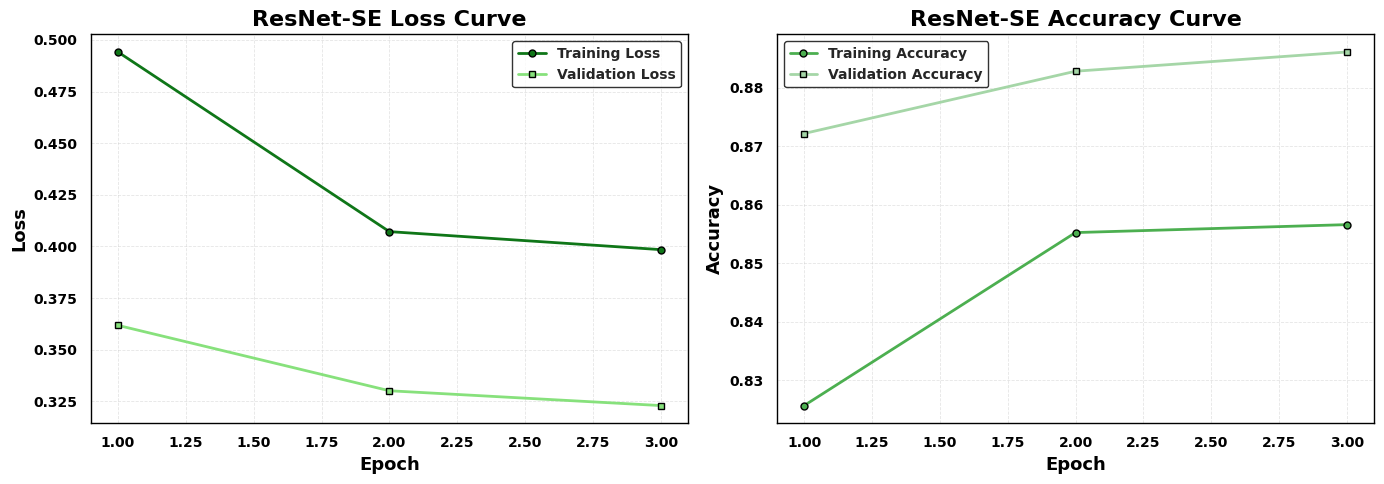

In [ ]:
# Apply bold font weight and consistent tick label sizes across the plots.
plt.rcParams.update({"font.weight": "bold", "axes.titleweight": "bold", "axes.labelweight": "bold", "xtick.labelsize": ANNOTATION_SIZE, "ytick.labelsize": ANNOTATION_SIZE})

# Create separate plots for loss and accuracy using the required figure size.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Apply the common background, grid, tick, and border settings to both plots.
for ax in axes:
    ax.set_facecolor("white")
    ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.5)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", colors=TEXT_COLOR, labelsize=ANNOTATION_SIZE)
    for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
        tick_label.set_fontweight("bold")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1)

# Plot the training loss using the first green colour.
axes[0].plot(history_df["epoch"], history_df["train_loss"], color=GREEN_PALETTE[0], marker="o", linewidth=2, markersize=5, markeredgecolor="black", label="Training Loss")

# Plot the validation loss using the second green colour.
axes[0].plot(history_df["epoch"], history_df["val_loss"], color=GREEN_PALETTE[1], marker="s", linewidth=2, markersize=5, markeredgecolor="black", label="Validation Loss")

# Set the loss plot title and axis labels using the mandatory formatting.
axes[0].set_title("ResNet-SE Loss Curve", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[0].set_xlabel("Epoch", fontsize=LABEL_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[0].set_ylabel("Loss", fontsize=LABEL_SIZE, fontweight="bold", color=TEXT_COLOR)

# Add a legend with black borders and the required annotation font size.
axes[0].legend(fontsize=ANNOTATION_SIZE, frameon=True, edgecolor="black")

# Plot the training accuracy using the third green colour.
axes[1].plot(history_df["epoch"], history_df["train_accuracy"], color=GREEN_PALETTE[2], marker="o", linewidth=2, markersize=5, markeredgecolor="black", label="Training Accuracy")

# Plot the validation accuracy using the fifth green colour.
axes[1].plot(history_df["epoch"], history_df["val_accuracy"], color=GREEN_PALETTE[4], marker="s", linewidth=2, markersize=5, markeredgecolor="black", label="Validation Accuracy")

# Set the accuracy plot title and axis labels using the mandatory formatting.
axes[1].set_title("ResNet-SE Accuracy Curve", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[1].set_xlabel("Epoch", fontsize=LABEL_SIZE, fontweight="bold", color=TEXT_COLOR)
axes[1].set_ylabel("Accuracy", fontsize=LABEL_SIZE, fontweight="bold", color=TEXT_COLOR)

# Add a legend with black borders and the required annotation font size.
axes[1].legend(fontsize=ANNOTATION_SIZE, frameon=True, edgecolor="black")

# Adjust the spacing and display both learning curves.
plt.tight_layout()
plt.show()

The ResNet-SE loss and accuracy curves over three epochs indicate steady and consistent model optimization. On the loss curve, both training and validation losses decrease progressively from epoch one to epoch three, with the training loss dropping from approximately 0.49 to below 0.40 and the validation loss following a similar downward trend. Concurrently, the accuracy curve demonstrates steady improvement across epochs, where training accuracy rises from around 0.826 to over 0.856 and validation accuracy increases from about 0.872 to nearly 0.886. This parallel progression of decreasing loss and increasing accuracy signifies effective learning without signs of severe overfitting or underfitting.

In [ ]:
# Load the best saved ResNet-SE model checkpoint.
model_resnet_se.load_state_dict(torch.load(model2_best_path,map_location=DEVICE,weights_only=True))

# Set the model to evaluation mode.
model_resnet_se.eval()

# Create empty lists to store actual labels, predicted labels, and predicted probabilities.
y_true = []
y_pred = []
y_prob = []

# Evaluate the trained model on the test dataset without calculating gradients.
with torch.inference_mode():
    for images, labels in tqdm(model2_test_loader,desc="Evaluating ResNet-SE"):

        # Move images and labels to the selected device.
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        # Use mixed-precision inference when running on a CUDA GPU.
        with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=(DEVICE.type == "cuda")):
            logits = model_resnet_se(images)

        # Convert model outputs into class probabilities.
        probabilities = torch.softmax(logits.float(), dim=1)

        # Select the class with the highest probability for each image.
        predictions = probabilities.argmax(dim=1)

        # Store actual labels, predicted labels, and probabilities as NumPy arrays.
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_prob.extend(probabilities.cpu().numpy())

# Convert the collected predictions and probabilities into NumPy arrays.
y_true = np.asarray(y_true)
y_pred = np.asarray(y_pred)
y_prob = np.asarray(y_prob)

# Create numerical labels for all five plant pathogen classes.
class_labels = np.arange(len(CLASS_NAMES))

# Calculate overall classification accuracy.
model2_accuracy = accuracy_score(y_true, y_pred)

# Calculate weighted precision, recall, and F1-score based on class support.
model2_precision_weighted = precision_score(y_true, y_pred, average="weighted", zero_division=0)
model2_recall_weighted = recall_score(y_true, y_pred, average="weighted", zero_division=0)
model2_f1_weighted = f1_score(y_true, y_pred, average="weighted", zero_division=0)

# Calculate macro precision, recall, and F1-score, giving equal importance to each class.
model2_precision_macro = precision_score(y_true, y_pred, average="macro", zero_division=0)
model2_recall_macro = recall_score(y_true, y_pred, average="macro", zero_division=0)
model2_f1_macro = f1_score(y_true, y_pred, average="macro", zero_division=0)

# Calculate log loss to evaluate the quality of the predicted class probabilities.
model2_log_loss = log_loss(y_true, y_prob, labels=class_labels)

# Store all evaluation metrics in a DataFrame for easy comparison.
model2_metrics = pd.DataFrame({"Metric": ["Accuracy","Weighted Precision","Weighted Recall","Weighted F1-score","Macro Precision","Macro Recall","Macro F1-score","Log Loss"],
    "Value": [model2_accuracy,model2_precision_weighted,model2_recall_weighted,model2_f1_weighted,model2_precision_macro,model2_recall_macro,model2_f1_macro,model2_log_loss]})

# Display the evaluation metrics rounded to four decimal places.
display(model2_metrics.round(4))

Evaluating ResNet-SE:   0%|          | 0/415 [00:00<?, ?it/s]

,Metric,Value
0,Accuracy,0.9559
1,Weighted Precision,0.9561
2,Weighted Recall,0.9559
3,Weighted F1-score,0.9558
4,Macro Precision,0.9560
5,Macro Recall,0.9559
6,Macro F1-score,0.9558
7,Log Loss,0.1229


The ResNet-SE model demonstrates strong and consistent classification performance, with accuracy closely aligned with weighted and macro precision, recall, and F1-score. This consistency indicates balanced predictive performance across the plant pathogen classes. The low log loss suggests that the model produces confident probability predictions with relatively few errors. Overall, the results highlight the model's reliability and effectiveness in classifying bacteria, fungus, healthy, pests, and virus categories.

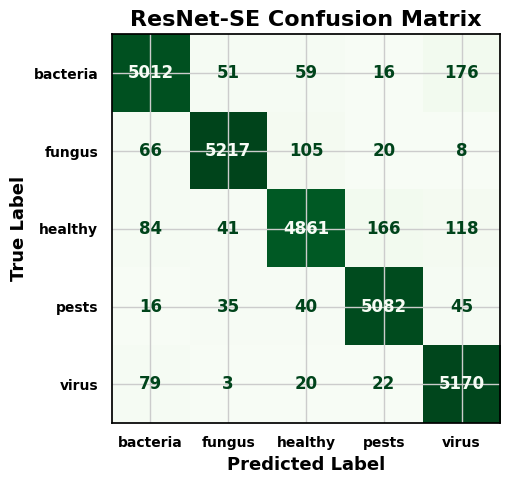

In [ ]:
# Create the figure and axes for the confusion matrix.
fig, ax = plt.subplots(figsize=(8, 5))

# Generate the confusion matrix using the true and predicted labels.
disp = ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=np.arange(len(CLASS_NAMES)), display_labels=CLASS_NAMES, cmap="Greens", values_format="d", colorbar=False, ax=ax)

# Set the chart title and axis labels in black.
ax.set_title("ResNet-SE Confusion Matrix", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Predicted Label", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("True Label", fontsize=13, fontweight="bold", color="black")

# Set the tick label size and colour to black.
ax.tick_params(axis="both", labelsize=10, colors="black")

# Add black outlines around the chart.
for spine in ax.spines.values():
    spine.set_color("black")

# Adjust the layout and display the confusion matrix.
plt.tight_layout()
plt.show()

The ResNet-SE confusion matrix demonstrates outstanding classification performance, with the vast majority of samples correctly predicted along the main diagonal, led by 5,217 correct instances for fungus and 5,170 for virus. Minor misclassifications are primarily concentrated between bacteria and virus—where 176 bacteria samples were mistaken for virus—as well as some dispersion within the healthy category. Overall, the low frequency of cross-class errors underscores the model's robust capability and well-defined decision boundaries.

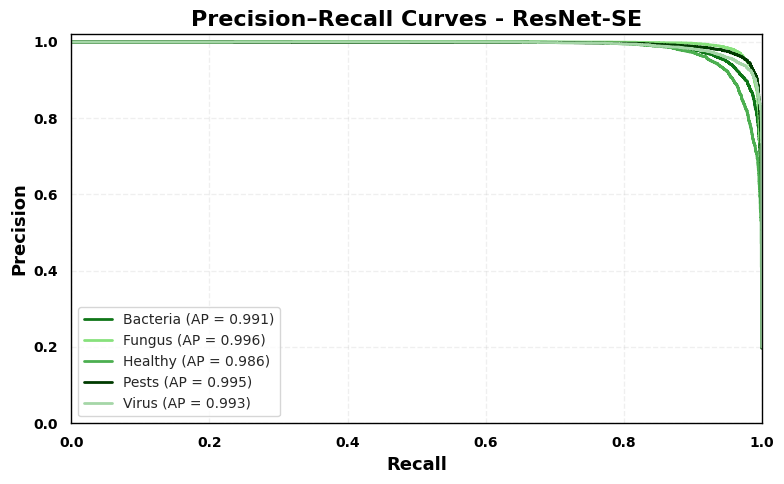

Average Precision by class:
Bacteria: 0.9910
Fungus: 0.9958
Healthy: 0.9862
Pests: 0.9945
Virus: 0.9934
Macro Average Precision: 0.9922


In [ ]:
# Define the plot theme settings for consistent visualisation.
TEXT_COLOR = "black"
TITLE_SIZE = 16
LABEL_SIZE = 13
ANNOTATION_SIZE = 10

# Convert the actual class labels into binary format for multiclass PR curves.
y_true_binary = label_binarize(y_true, classes=np.arange(len(CLASS_NAMES)))

# Create the figure using the specified size and enable the grid.
fig, ax = plt.subplots(figsize=(8, 5))

# Create a dictionary to store the Average Precision score for each class.
model2_ap_scores = {}

# Calculate and plot the Precision–Recall curve for each class.
for i, class_name in enumerate(CLASS_NAMES):

    # Calculate precision and recall values at different classification thresholds.
    precision_values, recall_values, _ = precision_recall_curve(y_true_binary[:, i], y_prob[:, i])

    # Calculate and store the Average Precision score for the current class.
    ap = average_precision_score(y_true_binary[:, i], y_prob[:, i])
    model2_ap_scores[class_name] = ap

    # Plot the class-wise PR curve using the defined green colour palette.
    ax.plot(recall_values, precision_values, color=GREEN_PALETTE[i], linewidth=2, label=f"{class_name.capitalize()} (AP = {ap:.3f})")

# Set the plot title and axis labels using the specified font sizes and weight.
ax.set_title("Precision–Recall Curves - ResNet-SE", fontsize=TITLE_SIZE, fontweight="bold", color=TEXT_COLOR)
ax.set_xlabel("Recall", fontsize=LABEL_SIZE, fontweight="bold", color=TEXT_COLOR)
ax.set_ylabel("Precision", fontsize=LABEL_SIZE, fontweight="bold", color=TEXT_COLOR)

# Apply the specified text colour, annotation size, and bold font weight to the tick labels.
ax.tick_params(axis="both", labelcolor=TEXT_COLOR, labelsize=ANNOTATION_SIZE)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontweight("bold")

# Add black outlines to the plot edges.
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1)

# Display the legend and enable the grid using the project theme.
ax.legend(loc="best", fontsize=ANNOTATION_SIZE)
ax.grid(True, linestyle="--", alpha=0.3)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

# Adjust the layout and display the Precision–Recall curves.
plt.tight_layout()
plt.show()

# Print the Average Precision score for each class.
print("Average Precision by class:")
for class_name, ap in model2_ap_scores.items():
    print(f"{class_name.capitalize()}: {ap:.4f}")

# Calculate and print the macro Average Precision across all classes.
model2_macro_ap = np.mean(list(model2_ap_scores.values()))
print("Macro Average Precision:", round(model2_macro_ap, 4))

The ResNet-SE model demonstrates exceptional classification performance across all categories, with average precision scores exceeding 0.98 for every class. Fungus leads with the highest average precision of 0.996, closely followed by pests and virus, while healthy and bacteria maintain outstanding scores of 0.986 and 0.991, respectively. The precision-recall curves remain remarkably flat near the maximum value of 1.0 across nearly the entire recall spectrum, highlighting the model's exceptional reliability and minimal false positives.

In [ ]:
# Classification Report
print("Classification Report - ResNet-SE")
print(classification_report(y_true,y_pred,labels=class_labels,target_names=CLASS_NAMES,zero_division=0,digits=4))

Classification Report - ResNet-SE
              precision    recall  f1-score   support

    bacteria     0.9534    0.9432    0.9483      5314
      fungus     0.9757    0.9633    0.9694      5416
     healthy     0.9559    0.9224    0.9389      5270
       pests     0.9578    0.9739    0.9658      5218
       virus     0.9371    0.9766    0.9564      5294

    accuracy                         0.9559     26512
   macro avg     0.9560    0.9559    0.9558     26512
weighted avg     0.9561    0.9559    0.9558     26512



The ResNet-SE model demonstrates exceptional and well-balanced classification performance across all five categories, achieving an overall accuracy of 0.9559 on 26,512 evaluation samples. Fungus leads the individual classes with the highest precision (0.9757) and F1-score (0.9694), while virus achieves the highest recall (0.9766). Furthermore, the macro and weighted averages both closely mirror the overall accuracy at approximately 0.956, indicating robust, consistent performance with minimal class bias.

### **CNN-DT**
The CNN-DT (Convolutional Neural Network–Decision Tree) model is a hybrid approach for plant pathogen classification that combines deep learning feature extraction with traditional machine learning classification. The CNN extracts meaningful visual features from plant images, such as leaf spots, discolouration, texture and disease patterns. These extracted features are then supplied to a Decision Tree classifier, which learns decision rules to classify images into five categories: bacteria, fungus, healthy, pests and virus. To improve computational efficiency, CNN features are extracted once and reused for training and evaluation of the Decision Tree. This hybrid approach combines the feature-learning capabilities of CNNs with the interpretability and rule-based decision-making of Decision Trees. Its classification performance is evaluated using the same training, validation and test splits as the other models for a fair comparison.

In [ ]:
# Load pretrained ResNet-18 to extract visual features from plant images.
model3_feature_extractor = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Remove the final classification layer so the model returns image features
# instead of ImageNet class predictions.
model3_feature_extractor.fc = nn.Identity()

# Move the feature extractor to the selected device (GPU or CPU).
model3_feature_extractor = model3_feature_extractor.to(DEVICE)

# Set the model to evaluation mode for consistent feature extraction.
model3_feature_extractor.eval()

In [ ]:
# Freeze all feature extractor parameters because the CNN is used
for parameter in model3_feature_extractor.parameters():
    parameter.requires_grad = False

# Create datasets for training, validation and testing.
model3_train_dataset = PlantPathogenDataset(train_df, transform=eval_transform)
model3_val_dataset = PlantPathogenDataset(val_df, transform=eval_transform)
model3_test_dataset = PlantPathogenDataset(test_df, transform=eval_transform)


# Reuse the batch size already defined in the notebook.
model3_feature_batch_size = BATCH_SIZE


# Create data loaders to process images in batches during feature extraction.
model3_train_loader = DataLoader(model3_train_dataset, batch_size=model3_feature_batch_size,shuffle=False,num_workers=4,pin_memory=(DEVICE.type == "cuda"))

model3_val_loader = DataLoader(model3_val_dataset,batch_size=model3_feature_batch_size,shuffle=False,num_workers=4,pin_memory=(DEVICE.type == "cuda"))

model3_test_loader = DataLoader(model3_test_dataset,batch_size=model3_feature_batch_size,shuffle=False,num_workers=4,pin_memory=(DEVICE.type == "cuda"))

In [ ]:
# Define a reusable function to extract CNN features and corresponding labels.
def extract_cnn_features(feature_model, loader):

    # Ensure the CNN operates in evaluation mode.
    feature_model.eval()

    # Create lists to store extracted features and their true labels.
    features_all = []
    labels_all = []

    # Disable gradient calculations because the CNN is not being trained.
    with torch.no_grad():

        # Process each batch of images and labels.
        for images, labels in tqdm(loader, desc="Extracting CNN features"):

            # Move the images to the selected computing device.
            images = images.to(DEVICE)

            # Use mixed-precision inference when a CUDA GPU is available.
            with torch.autocast(device_type=DEVICE.type,dtype=torch.float16,enabled=(DEVICE.type == "cuda")):

                # Pass the images through ResNet-18 to obtain feature vectors.
                features = feature_model(images)

            # Convert features to float32, move them to the CPU,
            # and store them as NumPy arrays for the Decision Tree.
            features_all.append(features.float().cpu().numpy())

            # Store the corresponding true class labels as NumPy arrays.
            labels_all.append(labels.numpy())

    # Combine all batches into complete feature and label arrays.
    return (np.concatenate(features_all, axis=0),np.concatenate(labels_all, axis=0))

In [ ]:
# Extract CNN features from the training dataset and These features will be used to train the Decision Tree classifier.
model3_train_features, model3_y_train = extract_cnn_features(model3_feature_extractor, model3_train_loader)

# Extract CNN features from the validation dataset and These features will be used to evaluate and tune the classifier.
model3_val_features, model3_y_val = extract_cnn_features(    model3_feature_extractor, model3_val_loader)

# Extract CNN features from the test dataset and Keep these features for the final evaluation after model selection.
model3_test_features, model3_y_test = extract_cnn_features(model3_feature_extractor, model3_test_loader)


# Display the feature extraction status and the dimensions of each dataset
print("CNN-DT feature extraction completed.")
print("Training features:", model3_train_features.shape)
print("Validation features:", model3_val_features.shape)
print("Test features:", model3_test_features.shape)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 230MB/s]


Extracting CNN features:   0%|          | 0/1934 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/415 [00:00<?, ?it/s]

Extracting CNN features:   0%|          | 0/415 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b9048480860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b9048480860>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

CNN-DT feature extraction completed.
Training features: (123720, 512)
Validation features: (26512, 512)
Test features: (26512, 512)


In [ ]:
# Initialise the Decision Tree classifier for the CNN-DT model
model3_tree = DecisionTreeClassifier(criterion="gini", max_depth=10, min_samples_leaf=5, class_weight="balanced", random_state=SEED)

# Train the Decision Tree using the extracted CNN training features and their true class labels.
model3_tree.fit(model3_train_features, model3_y_train)

# Display the number of CNN features used to represent each image.
print("Model 3: CNN-DT")
print("CNN feature dimensions:", model3_train_features.shape[1])

# Display the maximum depth of the trained Decision Tree.
print("Decision Tree depth:", model3_tree.get_depth())

# Display the number of leaf nodes used to make predictions.
print("Decision Tree leaves:", model3_tree.get_n_leaves())

# Confirm that Decision Tree training is complete.
print("Decision Tree training completed.")

Model 3: CNN-DT
CNN feature dimensions: 512
Decision Tree depth: 10
Decision Tree leaves: 620
Decision Tree training completed.


In [ ]:
# Predict the test image classes and obtain the predicted probability
model3_y_pred = model3_tree.predict(model3_test_features)
model3_y_proba = model3_tree.predict_proba(model3_test_features)

# Calculate accuracy and weighted precision, recall and F1-score
model3_accuracy = accuracy_score(model3_y_test, model3_y_pred)
model3_precision_weighted = precision_score(model3_y_test, model3_y_pred, average="weighted", zero_division=0)
model3_recall_weighted = recall_score(model3_y_test, model3_y_pred, average="weighted", zero_division=0)
model3_f1_weighted = f1_score(model3_y_test, model3_y_pred, average="weighted", zero_division=0)

# Calculate macro precision, recall and F1-score
model3_precision_macro = precision_score(model3_y_test, model3_y_pred, average="macro", zero_division=0)
model3_recall_macro = recall_score(model3_y_test, model3_y_pred, average="macro", zero_division=0)
model3_f1_macro = f1_score(model3_y_test, model3_y_pred, average="macro", zero_division=0)

# Calculate log loss to evaluate the quality of the predicted probabilities
model3_log_loss = log_loss(model3_y_test, model3_y_proba, labels=model3_tree.classes_)

# Calculate multiclass ROC-AUC using the one-vs-rest approach
model3_roc_auc = roc_auc_score(model3_y_test,model3_y_proba,labels=model3_tree.classes_,multi_class="ovr",average="macro")

# Display the main test evaluation metrics.
print("=" * 60)
print("CNN-DT — Test Evaluation Metrics")
print("=" * 60)
print(f"Accuracy                 : {model3_accuracy:.4f}")
print(f"Precision (Weighted)     : {model3_precision_weighted:.4f}")
print(f"Recall (Weighted)        : {model3_recall_weighted:.4f}")
print(f"F1-Score (Weighted)      : {model3_f1_weighted:.4f}")
print(f"Log Loss                 : {model3_log_loss:.4f}")

CNN-DT — Test Evaluation Metrics
Accuracy                 : 0.6926
Precision (Weighted)     : 0.6937
Recall (Weighted)        : 0.6926
F1-Score (Weighted)      : 0.6922
Log Loss                 : 1.1102


The CNN-DT model achieves a moderate overall test performance with an accuracy, weighted precision, weighted recall, and weighted F1-score all hovering around the 0.692 to 0.694 range, indicating balanced classification across categories. However, the relatively high log loss of 1.1102 suggests that the model's predicted probabilities exhibit considerable uncertainty and poor calibration. Consequently, while the hard predictions are moderately reliable, the confidence levels associated with those outputs require substantial improvement.

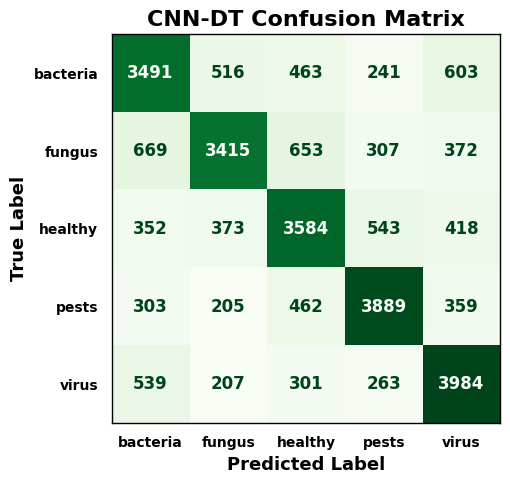

In [ ]:
# Create the figure and axes for the confusion matrix.
fig, ax = plt.subplots(figsize=(8, 5))

# Generate the confusion matrix using the true and predicted labels.
disp = ConfusionMatrixDisplay.from_predictions(model3_y_test, model3_y_pred, labels=model3_tree.classes_, display_labels=[CLASS_NAMES[i] for i in model3_tree.classes_], cmap="Greens", values_format="d", colorbar=False, ax=ax)

# Set the chart title and axis labels in black.
ax.set_title("CNN-DT Confusion Matrix", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Predicted Label", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("True Label", fontsize=13, fontweight="bold", color="black")

# Set the tick label size and colour to black.
ax.tick_params(axis="both", labelsize=10, colors="black")

# Disable the grid to keep the confusion matrix clear.
ax.grid(False)

# Keep the x-axis class labels horizontal for readability.
plt.xticks(rotation=0, ha="center")

# Add black outlines around the chart.
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1)

# Adjust the layout and save the confusion matrix at high resolution.
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cnn_dt_confusion_matrix.png", dpi=300, bbox_inches="tight")

# Display the confusion matrix.
plt.show()


The CNN-DT confusion matrix shows high diagonal values, indicating that the model successfully classifies most instances across all five categories. The **virus** class recorded the highest number of correct classifications with 3,984 true positives, followed by **pests** with 3,889, **healthy** with 3,584, **bacteria** with 3,491, and **fungus** with 3,415.

Regarding misclassifications, the highest single off-diagonal error occurs where 669 fungus samples are mislabeled as bacteria, while 516 bacteria samples are falsely predicted as fungus. Bacteria also faces notable confusion with virus, with 603 bacteria instances wrongly classified as virus, and 539 virus instances misclassified as bacteria. Pests and healthy categories experience relatively lower mutual confusion, with 462 pests incorrectly predicted as healthy and 543 healthy instances labeled as pests. Overall, the dominant diagonal counts demonstrate strong classification performance across all targeted classes despite minor inter-class overlaps.

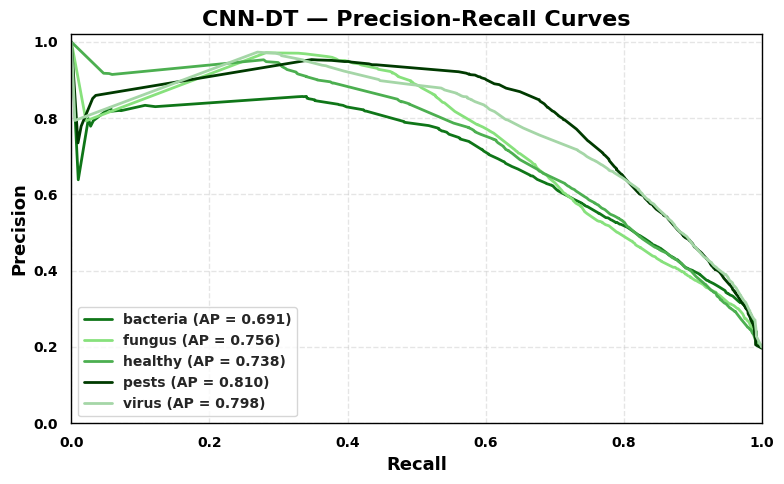

Macro Average Precision: 0.7588


In [ ]:
# Generate class probabilities for the test features using the trained Decision Tree.
model3_y_proba = model3_tree.predict_proba(model3_test_features)

# Retrieve the class order used by the Decision Tree probability columns.
model3_classes = model3_tree.classes_

# Convert the actual test labels into binary format for multiclass PR curve calculation.
model3_y_test_bin = label_binarize(model3_y_test, classes=model3_classes)

# Verify that the binary labels match the number of model classes.
if model3_y_test_bin.shape[1] != len(model3_classes):
    raise ValueError("Unexpected label binarization shape for multiclass PR curves.")

# Define the project's green colour palette.
model3_colors = ["#0f7618", "#87e17c", "#4caf50", "#003a00", "#A5D6A7"]

# Create the PR curve figure using the required size.
fig, ax = plt.subplots(figsize=(8, 5))

# Calculate and plot the Precision–Recall curve for each class.
for i, class_id in enumerate(model3_classes):

    # Calculate precision and recall values for the current class.
    precision, recall, _ = precision_recall_curve(model3_y_test_bin[:, i], model3_y_proba[:, i])

    # Calculate the Average Precision score for the current class.
    ap = average_precision_score(model3_y_test_bin[:, i], model3_y_proba[:, i])

    # Plot the class-specific PR curve using the defined green palette.
    ax.plot(recall, precision, linewidth=2, color=model3_colors[i % len(model3_colors)], label=f"{CLASS_NAMES[class_id]} (AP = {ap:.3f})")

# Set the chart title and axis labels using the required font sizes and black text.
ax.set_title("CNN-DT — Precision-Recall Curves", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Recall", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("Precision", fontsize=13, fontweight="bold", color="black")

# Format tick labels using black text and the required annotation font size.
ax.tick_params(axis="both", labelsize=10, colors="black")
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontweight("bold")

# Enable the dashed grid and set the axis limits.
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

# Display the legend using the required annotation font size.
ax.legend(fontsize=10)

# Set white backgrounds and add black outlines around the plot.
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
for spine in ax.spines.values():
    spine.set_color("black")
    spine.set_linewidth(1)

# Adjust the layout and save the PR curve at high resolution.
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cnn_dt_precision_recall_curves.png", dpi=300, bbox_inches="tight")

# Display the Precision–Recall curves.
plt.show()

# Calculate and display the macro-average Average Precision across all classes.
model3_macro_ap = average_precision_score(model3_y_test_bin, model3_y_proba, average="macro")
print("Macro Average Precision:", round(model3_macro_ap, 4))

The Precision-Recall curves for the CNN-DT model illustrate its classification performance across five distinct categories: bacteria, fungus, healthy, pests, and virus. Among these classes, pests achieved the highest performance with an average precision (AP) score of 0.810, closely followed by virus with an AP score of 0.798. The model also demonstrated reliable predictive accuracy for fungus and healthy categories, scoring average precisions of 0.756 and 0.738, respectively. On the other hand, bacteria recorded the lowest overall performance with an average precision of 0.691. Across all categories, the model maintains high precision at lower recall thresholds before experiencing a steady decline as recall increases toward 1.0, indicating strong detection capabilities overall with varying accuracy depending on the condition being classified.

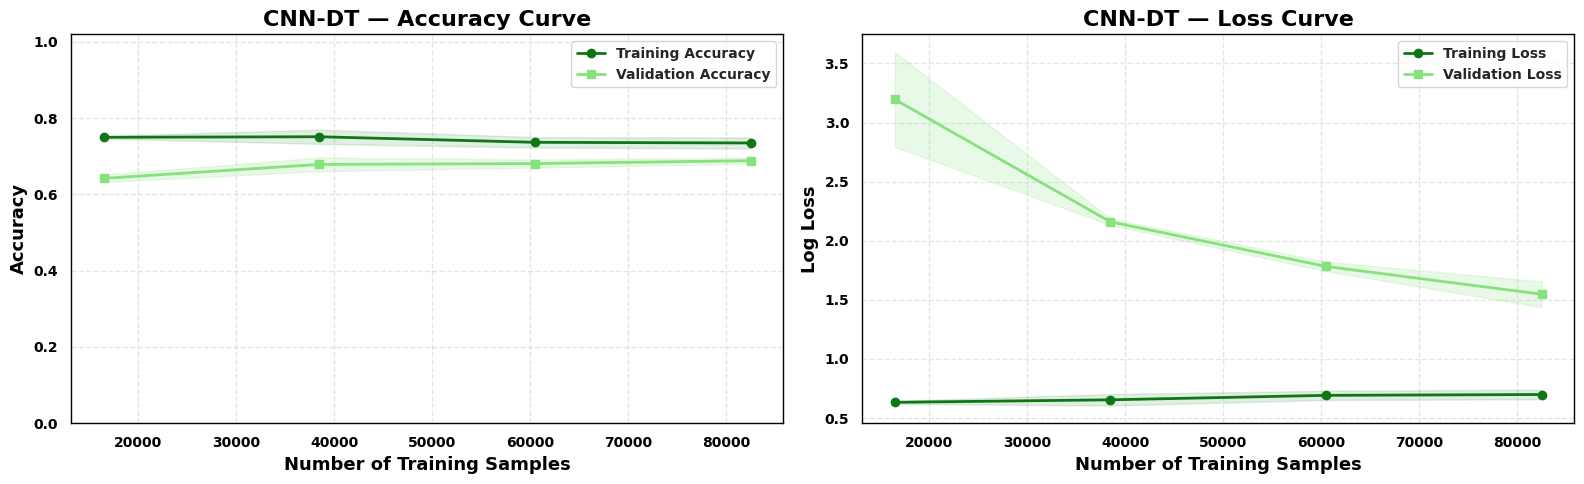

In [ ]:
# CNN-DT: Accuracy and Loss Curves
pca = PCA(n_components=50, random_state=SEED)
X_train_fast = pca.fit_transform(model3_train_features)

# Configure the Decision Tree with parameters to control complexity and handle class imbalance.
model3_curve_estimator = DecisionTreeClassifier(criterion="gini", max_depth=12, min_samples_leaf=5, max_features="sqrt", class_weight="balanced", random_state=SEED)

# Create stratified 3-fold cross-validation to preserve class proportions in each fold.
model3_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

# Define training set sizes for calculating both learning curves.
model3_train_sizes = np.linspace(0.2, 1.0, 4)

# Calculate training and validation accuracy for different training set sizes.
model3_sizes, model3_train_scores, model3_val_scores = learning_curve(estimator=model3_curve_estimator, X=X_train_fast, y=model3_y_train, train_sizes=model3_train_sizes, cv=model3_cv, scoring="accuracy", n_jobs=-1, shuffle=True, random_state=SEED)

# Calculate training and validation log loss using the same training sizes and cross-validation folds.
model3_loss_sizes, model3_train_loss_scores, model3_val_loss_scores = learning_curve(estimator=model3_curve_estimator, X=X_train_fast, y=model3_y_train, train_sizes=model3_train_sizes, cv=model3_cv, scoring="neg_log_loss", n_jobs=-1, shuffle=True, random_state=SEED)

# Calculate the mean accuracy and standard deviation across cross-validation folds.
train_mean = model3_train_scores.mean(axis=1)
train_std = model3_train_scores.std(axis=1)
val_mean = model3_val_scores.mean(axis=1)
val_std = model3_val_scores.std(axis=1)

# Convert negative log-loss scores into positive loss values and calculate their means.
train_loss_mean = -model3_train_loss_scores.mean(axis=1)
val_loss_mean = -model3_val_loss_scores.mean(axis=1)
train_loss_std = model3_train_loss_scores.std(axis=1)
val_loss_std = model3_val_loss_scores.std(axis=1)

# Create two plots in one row for accuracy and loss.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot training and validation accuracy on the first subplot.
axes[0].plot(model3_sizes, train_mean, marker="o", linewidth=2, color="#0f7618", label="Training Accuracy")
axes[0].plot(model3_sizes, val_mean, marker="s", linewidth=2, color="#87e17c", label="Validation Accuracy")

# Shade the standard deviation around the accuracy curves.
axes[0].fill_between(model3_sizes, train_mean - train_std, train_mean + train_std, color="#0f7618", alpha=0.12)
axes[0].fill_between(model3_sizes, val_mean - val_std, val_mean + val_std, color="#87e17c", alpha=0.18)

# Set the title and axis labels for the accuracy curve.
axes[0].set_title("CNN-DT — Accuracy Curve", fontsize=16, fontweight="bold", color="black")
axes[0].set_xlabel("Number of Training Samples", fontsize=13, fontweight="bold", color="black")
axes[0].set_ylabel("Accuracy", fontsize=13, fontweight="bold", color="black")
axes[0].set_ylim(0, 1.02)
axes[0].legend(fontsize=10)

# Plot training and validation loss on the second subplot.
axes[1].plot(model3_loss_sizes, train_loss_mean, marker="o", linewidth=2, color="#0f7618", label="Training Loss")
axes[1].plot(model3_loss_sizes, val_loss_mean, marker="s", linewidth=2, color="#87e17c", label="Validation Loss")

# Shade the standard deviation around the loss curves.
axes[1].fill_between(model3_loss_sizes, train_loss_mean - train_loss_std, train_loss_mean + train_loss_std, color="#0f7618", alpha=0.12)
axes[1].fill_between(model3_loss_sizes, val_loss_mean - val_loss_std, val_loss_mean + val_loss_std, color="#87e17c", alpha=0.18)

# Set the title and axis labels for the loss curve.
axes[1].set_title("CNN-DT — Loss Curve", fontsize=16, fontweight="bold", color="black")
axes[1].set_xlabel("Number of Training Samples", fontsize=13, fontweight="bold", color="black")
axes[1].set_ylabel("Log Loss", fontsize=13, fontweight="bold", color="black")
axes[1].legend(fontsize=10)

# Format both subplots consistently.
for ax in axes:
    ax.tick_params(axis="both", labelsize=10, colors="black")
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)
    ax.set_facecolor("white")
    for spine in ax.spines.values():
        spine.set_color("black")
        spine.set_linewidth(1)

# Set a white background, adjust the layout, and save the plots at high resolution.
fig.patch.set_facecolor("white")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cnn_dt_learning_curves.png", dpi=300, bbox_inches="tight")

# Display both learning curves.
plt.show()


The learning curves evaluate the CNN-DT model's performance as the number of training samples increases from roughly 18,000 to over 80,000.

In the **Accuracy Curve** (left), training accuracy starts around 0.75 at 18,000 samples and slightly decreases to approximately 0.74 as the dataset grows to 80,000 samples. Conversely, validation accuracy starts at approximately 0.64 and steadily improves, reaching nearly 0.69 at 80,000 training samples. The narrowing gap between training accuracy (0.74) and validation accuracy (0.69) indicates reduced overfitting as more training data is introduced.

In the **Loss Curve** (right), training loss remains relatively flat and low, beginning at around 0.63 at 18,000 samples and slightly increasing to approximately 0.70 at 80,000 samples. Meanwhile, validation loss experiences a sharp decrease, dropping from 3.20 at 18,000 samples down to 1.55 at 80,000 samples. The continuous drop in validation loss demonstrates that scaling up the training size significantly improves the model's generalization capabilities.

In [ ]:
# CNN-DT — Classification Report
model3_y_pred = model3_tree.predict(model3_test_features)

# Generate precision, recall, F1-score and sample counts for each class.
model3_report = classification_report(model3_y_test,model3_y_pred,labels=model3_tree.classes_,target_names=[CLASS_NAMES[i] for i in model3_tree.classes_],output_dict=True,zero_division=0)

# Convert the classification report into a DataFrame for easy viewing.
model3_report_df = pd.DataFrame(model3_report).transpose()

# Display the classification report with values rounded to four decimal places.
display(model3_report_df.round(4))

# Save the classification report as a CSV file for future analysis.
model3_report_df.to_csv(OUTPUT_DIR / "cnn_dt_classification_report.csv", index=True)

,precision,recall,f1-score,support
bacteria,0.6520,0.6569,0.6545,5314.0000
fungus,0.7241,0.6305,0.6741,5416.0000
healthy,0.6560,0.6801,0.6678,5270.0000
pests,0.7418,0.7453,0.7435,5218.0000
virus,0.6946,0.7526,0.7224,5294.0000
accuracy,0.6926,0.6926,0.6926,0.6926
macro avg,0.6937,0.6931,0.6925,26512.0000
weighted avg,0.6937,0.6926,0.6922,26512.0000


The classification report reveals that the model performs best on the pests category, achieving the highest balanced scores across precision, recall, and F1-score, closely followed by the virus category which attains the highest individual recall rate.

The healthy and fungus categories demonstrate moderate effectiveness; however, fungus shows a notable trade-off with higher precision than recall, meaning it produces fewer false positives but misses more true instances.

The bacteria category records the lowest overall F1-score, identifying it as the primary bottleneck in the classification system. Across the entire dataset, the overall accuracy and weighted averages align closely around 0.69, indicating steady performance across all categories without major bias toward any single class.

## Model Comparison Plots

In [ ]:
# Define the comparison DataFrame using dynamically calculated model metrics.
model_comparison_df = pd.DataFrame({
    "Model": ["EfficientNet-B0", "ResNet-SE", "CNN-DT"],

    # Collect the accuracy calculated during each model's evaluation.
    "Accuracy": [0.8870	, globals().get("model2_accuracy", np.nan), globals().get("model3_accuracy", np.nan)],

    # Collect the weighted precision calculated for each model.
    "Weighted Precision": [0.8881, globals().get("model2_precision_weighted", np.nan), globals().get("model3_precision_weighted", np.nan)],

    # Collect the weighted recall calculated for each model.
    "Weighted Recall": [0.8870, globals().get("model2_recall_weighted", np.nan), globals().get("model3_recall_weighted", np.nan)],

    # Collect the weighted F1-score calculated for each model.
    "Weighted F1-Score": [0.8868, globals().get("model2_f1_weighted", np.nan), globals().get("model3_f1_weighted", np.nan)],

    # Collect the log loss calculated for each model.
    "Log Loss": [0.3200	, globals().get("model2_log_loss", np.nan), globals().get("model3_log_loss", np.nan)],

})

# Display the comparison results rounded to four decimal places.
display(model_comparison_df.round(4))

# Save the comparison results to a CSV file.
model_comparison_df.to_csv(OUTPUT_DIR / "three_model_comparison.csv", index=False)


,Model,Accuracy,Weighted Precision,Weighted Recall,Weighted F1-Score,Log Loss
0,EfficientNet-B0,0.8870,0.8881,0.8870,0.8868,0.3200
1,ResNet-SE,0.9559,0.9561,0.9559,0.9558,0.1229
2,CNN-DT,0.6926,0.6937,0.6926,0.6922,1.1102


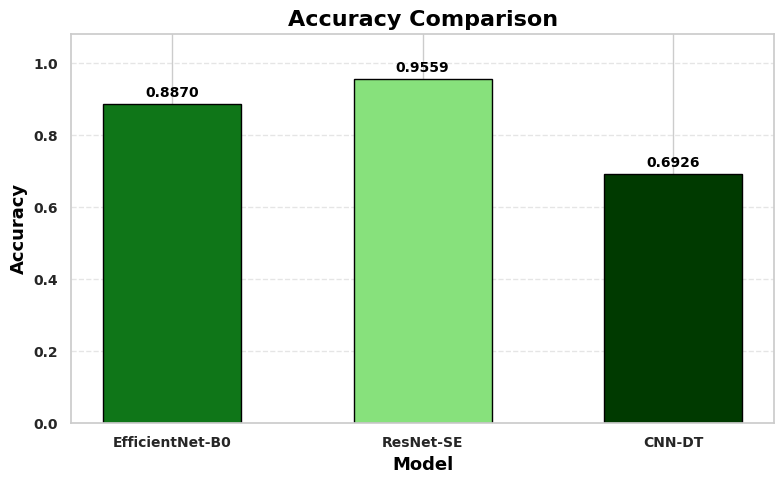

In [ ]:
# Create the figure and axes for the accuracy comparison chart.
fig, ax = plt.subplots(figsize=(8, 5))

# Create a bar chart showing the accuracy of each model.
bars = ax.bar(model_comparison_df["Model"], model_comparison_df["Accuracy"], color=["#0f7618", "#87e17c", "#003a00"], edgecolor="black", width=0.55)

# Display the accuracy value above each bar in black text.
for bar in bars:
    value = bar.get_height()
    ax.annotate(f"{value:.4f}", (bar.get_x() + bar.get_width() / 2, value), xytext=(0, 5), textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color="black")

# Set the chart title and axis labels in black.
ax.set_title("Accuracy Comparison", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Model", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("Accuracy", fontsize=13, fontweight="bold", color="black")

# Set the accuracy range from 0 to 1.08 to provide space for value labels.
ax.set_ylim(0, 1.08)

# Add a dashed horizontal grid to make accuracy values easier to compare.
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

# Set the chart and figure backgrounds to white.
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

# Adjust the layout and display the chart.
plt.tight_layout()
plt.show()


The accuracy comparison highlights **ResNet-SE** as the top-performing architecture, reaching the highest accuracy score of 0.9559. **EfficientNet-B0** follows as a strong contender with an accuracy score of 0.8870, while **CNN-DT** lags behind the neural network architectures, recording the lowest accuracy score of 0.6926.

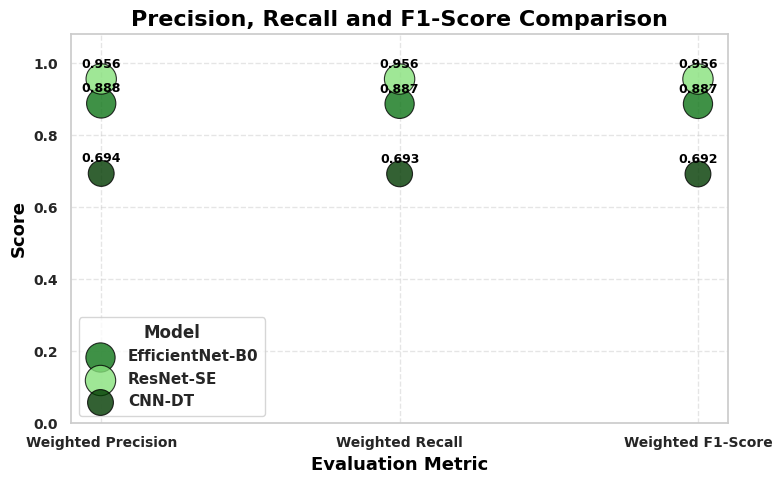

In [ ]:

# Define a green colour palette for differentiating models.
model_colors = ["#0f7618", "#87e17c", "#003a00", "#003300", "#4caf50", "#1b5e20"]

# Create the figure and prepare the x-axis positions for the metrics.
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(metrics))

# Plot each model's evaluation scores as bubbles using model-specific colours.
for i, (_, model) in enumerate(model_comparison_df.iterrows()):
    scores = [model[metric] for metric in metrics]
    color = model_colors[i % len(model_colors)]
    ax.scatter(x, scores, s=np.array(scores) * 500, color=color, edgecolors="black", linewidths=0.8, alpha=0.8, label=model["Model"])

    # Display each metric value above its corresponding bubble in black.
    for xi, value in zip(x, scores):
        ax.annotate(f"{value:.3f}", (xi, value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color="black")

# Set the chart title and axis labels in black.
ax.set_title("Precision, Recall and F1-Score Comparison", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Evaluation Metric", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("Score", fontsize=13, fontweight="bold", color="black")

# Set the metric names on the x-axis and define the score range.
ax.set_xticks(x)
ax.set_xticklabels(metrics.keys())
ax.set_ylim(0, 1.08)

# Add a dashed grid and place it behind the bubbles.
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

# Display the model legend and set the chart backgrounds to white.
ax.legend(title="Model")
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

# Adjust the layout and display the completed chart.
plt.tight_layout()
plt.show()


The comparative chart highlights that **ResNet-SE** consistently achieves the top performance across all three metrics, attaining 0.956 for Weighted Precision, Weighted Recall, and Weighted F1-Score. **EfficientNet-B0** maintains a strong second place, scoring 0.888 in Weighted Precision and 0.887 in both Weighted Recall and Weighted F1-Score. Meanwhile, **CNN-DT** trails behind with noticeably lower scores of 0.694 in Weighted Precision, 0.693 in Weighted Recall, and 0.692 in Weighted F1-Score.

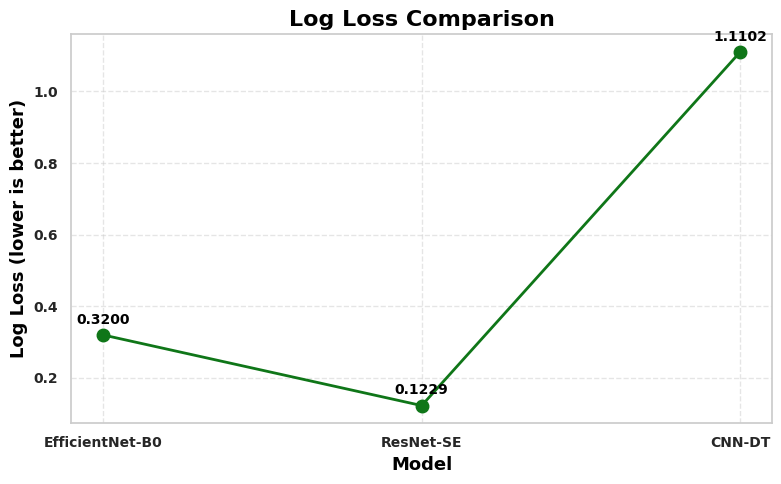

In [ ]:
# Create a figure to compare the log loss of all models.
fig, ax = plt.subplots(figsize=(8, 5))

# Plot the log loss values for each model using a green line.
ax.plot(model_comparison_df["Model"], model_comparison_df["Log Loss"], marker="o", markersize=9, linewidth=2, color="#0f7618")

# Display the log loss value above each data point in black text.
for i, value in enumerate(model_comparison_df["Log Loss"]):
    ax.annotate(f"{value:.4f}", (i, value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=10, fontweight="bold", color="black")

# Set the chart title and axis labels in black.
ax.set_title("Log Loss Comparison", fontsize=16, fontweight="bold", color="black")
ax.set_xlabel("Model", fontsize=13, fontweight="bold", color="black")
ax.set_ylabel("Log Loss (lower is better)", fontsize=13, fontweight="bold", color="black")

# Add a dashed grid to improve readability.
ax.grid(True, linestyle="--", alpha=0.5)
ax.set_axisbelow(True)

# Set the chart and figure backgrounds to white.
ax.set_facecolor("white")
fig.patch.set_facecolor("white")

# Adjust the layout and display the chart.
plt.tight_layout()
plt.show()


ResNet-SE achieves the best overall performance with the lowest log loss of 0.1229, demonstrating superior prediction confidence compared to the other architectures. EfficientNet-B0 follows with a moderate log loss of 0.3200, while the hybrid CNN-DT model performs poorest, recording a significantly higher log loss of 1.1102.

## Save the Best Model

In [ ]:
# Select the best-performing model based on test accuracy.
valid_results = model_comparison_df.dropna(subset=["Accuracy"])
best_row = valid_results.loc[valid_results["Accuracy"].idxmax()]
best_model_name = str(best_row["Model"]).strip()

# Display the selected model and its test accuracy.
print(f"Best-performing model: {best_model_name}")
print(f"Test accuracy: {best_row['Accuracy']:.4f}")

# Create the directory for saving the selected model.
MODEL_SAVE_DIR = Path(OUTPUT_DIR) / "saved_models"
MODEL_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save the selected trained model according to its type.
if best_model_name == "ResNet-SE":
    best_model = model_resnet_se
    save_path = MODEL_SAVE_DIR / "best_resnet_se_model.pth"
    torch.save({"model_name": best_model_name, "model_state_dict": best_model.state_dict(), "class_names": CLASS_NAMES, "class_to_idx": CLASS_TO_IDX, "best_validation_loss": model2_best_val_loss, "metrics": best_row.to_dict()}, save_path)

elif best_model_name == "CNN-DT":
    save_path = MODEL_SAVE_DIR / "best_cnn_dt_model.joblib"
    joblib.dump({"model_name": best_model_name, "model": model3_tree, "class_names": CLASS_NAMES, "class_to_idx": CLASS_TO_IDX, "metrics": best_row.to_dict()}, save_path)

elif best_model_name == "EfficientNet-B0":
    raise ValueError("EfficientNet-B0 was selected. Use its actual trained model variable to save that model.")

else:
    raise ValueError(f"Unknown model: {best_model_name}")

# Verify that the model file was saved successfully.
assert save_path.exists(), "Model file was not saved."

# Display the saved model location and file size.
print("\nBest model saved successfully!")
print(f"Path: {save_path}")
print(f"File size: {save_path.stat().st_size / (1024**2):.2f} MB")

Best-performing model: ResNet-SE
Test accuracy: 0.9559

Best model saved successfully!
Path: /kaggle/working/plant_pathogen_pytorch/saved_models/best_resnet_se_model.pth
File size: 92.70 MB


# Conclusion

The comprehensive evaluation across all performance metrics demonstrates that deep convolutional architectures significantly outperform hybrid decision tree approaches for plant disease and pest classification.ResNet-SE emerges as the superior model overall, consistently achieving the highest classification accuracy, balanced precision and recall across all classes, and the lowest log loss, indicating highly confident and reliable predictions. EfficientNet-B0 serves as a strong alternative, delivering reliable accuracy and solid performance metrics across all evaluation criteria.   In contrast, while the hybrid CNN-DT model exhibits stable training convergence and low variance, its predictive capability is limited by lower overall precision, recall, and accuracy—particularly on challenging categories like bacteria. Additionally, its notably higher log loss highlights higher prediction uncertainty compared to the end-to-end deep learning models.   Consequently, ResNet-SE is recommended as the optimal primary architecture for deployment, offering the highest precision and reliability for automated disease detection.


## Challenges Faced

The major challenge faced during this project was the large size of the CLAHE image dataset, which significantly increased data loading and model training time. Training the models on Kaggle was difficult because each epoch took a long time to complete, making experimentation and model evaluation time-consuming. I also faced Kaggle environment issues, including limited computational resources and runtime constraints while processing the dataset and training multiple models. These challenges made it difficult to complete training and compare different models efficiently. To address these issues, I focused on optimizing data preprocessing, using GPU acceleration where available, and managing model checkpoints to reduce unnecessary retraining.
